# V259 전력 예측 오류·피크 조건 분석

In [1]:
# Colab: 설치 → 런타임 재시작 → 다음 셀부터 실행
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'numpy==2.1.3', 'pandas==2.2.3',
                       'scipy==1.16.3', 'scikit-learn==1.6.1', 'threadpoolctl==3.7.0', 'cloudpickle', 'koreanize-matplotlib', 'arch==8.0.0'])
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pickle
from pathlib import Path

import cloudpickle
import numpy as np
import pandas as pd
import koreanize_matplotlib  # 한글 폰트
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from arch.bootstrap import StationaryBootstrap
from sklearn.metrics import average_precision_score, precision_recall_curve

ROOT = Path("/content/drive/MyDrive/kamp_2026")
PKL_PATH = ROOT / "models/v259_20261005_151309/v259_full_data.pkl"  # 기존 분석과 같은 모델 고정

# 01model 저장 pkl(모델 클래스·전처리 포함)
with Path(PKL_PATH).open("rb") as file:
    bundle = pickle.load(file)
model_v259 = bundle["model"]
INPUTS, POWER = bundle["input_columns"], bundle["target_columns"]
cv_scores = bundle["cv_scores"]
MONTHS = cv_scores.index.tolist()

raw = pd.read_csv(ROOT / "data/okm_augumented_2021.csv", encoding="utf-8-sig")
raw = raw.loc[raw["시간"].between(0, 23)].sort_values(["날짜", "시간"])
print("V259 pkl:", PKL_PATH)

# 시각화 공통 설정. 범주색 고정 순서, 배수(1 = 기준) 파랑–회색–빨강 발산색
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e4e3df", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, NEUTRAL, "#e34948"])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": .6, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 11, "axes.titleweight": "bold",
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})


def month_label(month):
    return f"{month % 100}월"


def ratio_heatmap(matrix, title):
    """배수 히트맵(1 초과 빨강, 미만 파랑). 유의성 표시는 하지 않음"""
    data = matrix.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(1.1 * data.shape[1] + 4, .32 * data.shape[0] + 1.3))
    norm = TwoSlopeNorm(vmin=0, vcenter=1, vmax=max(2, np.nanmax(data)))
    image = ax.imshow(data, cmap=DIVERGING, norm=norm, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(data.shape[1]), [month_label(m) if isinstance(m, (int, np.integer)) else m for m in matrix.columns])
    ax.set_yticks(range(data.shape[0]), matrix.index)
    for (i, j), value in np.ndenumerate(data):
        if np.isfinite(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color=INK, fontweight="normal")
    fig.colorbar(image, ax=ax, shrink=.8, label="배수 (1 = 기준)")
    ax.set_title(title)
    plt.show()


def ci_bars(ax, table, value, lower, upper, title):
    """배수 막대 + 95% 구간, 1 기준선"""
    position = np.arange(len(table))
    center = table[value].to_numpy(dtype=float)
    ax.bar(position, center, width=.7, color=BLUE)
    ax.vlines(position, table[lower], table[upper], color=INK, linewidth=1)
    ax.plot(position, table[lower], "_", color=INK, ms=5)
    ax.plot(position, table[upper], "_", color=INK, ms=5)
    ax.axhline(1, color=MUTED, ls=":", lw=1)
    ax.set_xticks(position, table.index.astype(str), rotation=45 if len(table) > 6 else 0, ha="right" if len(table) > 6 else "center")
    ax.set_title(title)

V259 pkl: /content/drive/MyDrive/kamp_2026/models/v259_20261005_151309/v259_full_data.pkl


### 검증 예측(OOF)

- 실제값·예측값 결합(원본 행 번호 기준)

In [3]:
# 4~8월 월별 CV 검증 예측 + 실제값(원본 행 번호 기준)
oof = raw.loc[bundle["oof"].index, INPUTS + POWER].join(bundle["oof"].add_prefix("pred_"))
oof["month"] = oof["날짜"].floordiv(100)
oof = oof.rename_axis("row_id").reset_index().sort_values(["month", "row_id"])
assert oof["row_id"].is_unique and not oof.duplicated(["날짜", "시간"]).any()
assert oof["month"].isin(MONTHS).all() and np.isfinite(oof[POWER + [f"pred_{p}" for p in POWER]]).all().all()


### 1. 월별 오차

- MAE·RMSE·편향, MSE 수준·형태 분해, Tukey 울타리(Q3 + 1.5·IQR)

,시간행수,날짜수,MAE,편향,과소예측비율,RMSE,수준오차비중_%,큰오차기준_MAE
month,,,,,,,,
202104,720,30,15.828,5.638,0.261,26.629,94.524,33.252
202105,744,31,11.252,-1.366,0.362,23.807,92.949,19.748
202106,720,30,11.836,-9.962,0.813,20.119,91.728,31.655
202107,696,29,12.786,-8.113,0.600,23.635,91.180,34.209
202108,744,31,8.235,-0.032,0.339,15.205,87.368,19.630


V259 월평균 CV MAE 11.987275


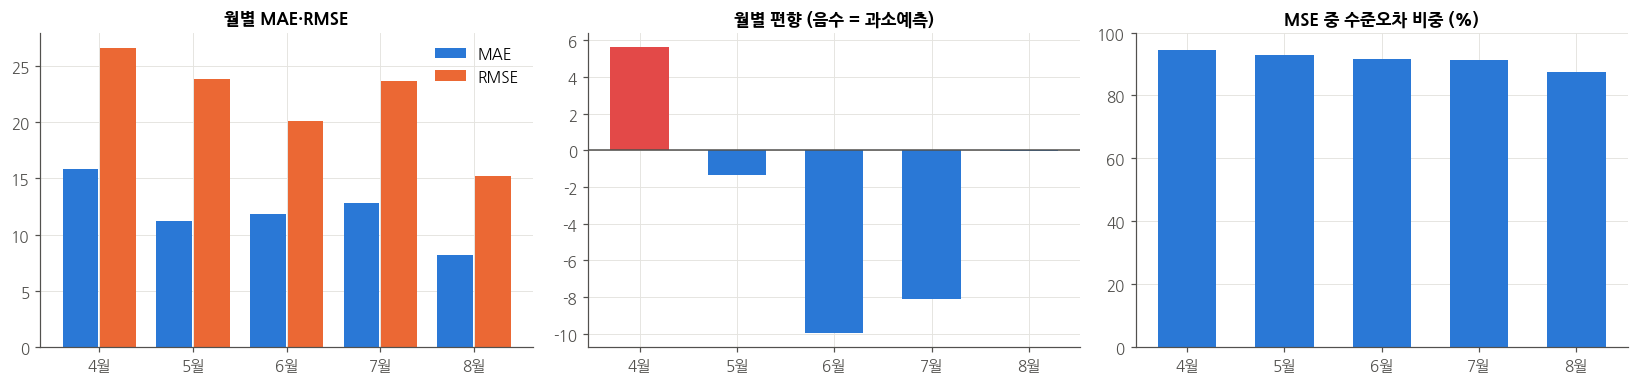

In [4]:
actual = oof[POWER].to_numpy(dtype=float)
prediction = oof[[f"pred_{p}" for p in POWER]].to_numpy(dtype=float)
error = prediction - actual  # 음수 = 과소예측, 양수 = 과대예측
errors = oof.copy()
errors["행_MAE"] = np.abs(error).mean(axis=1)
errors["행_MSE"] = np.square(error).mean(axis=1)
errors["편향"] = error.mean(axis=1)
# 행_MSE = 수준MSE(4개 오차 평균의 제곱) + 형태MSE(4개 오차의 시간 내 분산)
errors["수준MSE"] = errors["편향"] ** 2
errors["과소예측비율"] = (error < 0).mean(axis=1)
errors["실제평균"] = actual.mean(axis=1)
errors["예측평균"] = prediction.mean(axis=1)
# 큰오차: 월별 행_MAE의 Tukey 상단 울타리(Q3 + 1.5·IQR) 초과
monthly_q1 = errors.groupby("month")["행_MAE"].quantile(.25)
monthly_q3 = errors.groupby("month")["행_MAE"].quantile(.75)
big_error_fence = monthly_q3 + 1.5 * (monthly_q3 - monthly_q1)
errors["큰오차"] = errors["행_MAE"].gt(errors["month"].map(big_error_fence))

monthly = errors.groupby("month").agg(
    시간행수=("row_id", "size"), 날짜수=("날짜", "nunique"), MAE=("행_MAE", "mean"),
    MSE=("행_MSE", "mean"), 편향=("편향", "mean"), 과소예측비율=("과소예측비율", "mean"),
)
monthly["RMSE"] = np.sqrt(monthly.pop("MSE"))
monthly["수준오차비중_%"] = 100 * errors.groupby("month")["수준MSE"].sum() / errors.groupby("month")["행_MSE"].sum()
monthly["큰오차기준_MAE"] = big_error_fence
display(monthly.round(3))
print(f"V259 월평균 CV MAE {monthly['MAE'].mean():.6f}")

x = np.arange(len(MONTHS))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].bar(x - .2, monthly["MAE"], .38, color=BLUE, label="MAE")
axes[0].bar(x + .2, monthly["RMSE"], .38, color=ORANGE, label="RMSE")
axes[0].legend()
axes[0].set_title("월별 MAE·RMSE")
axes[1].bar(x, monthly["편향"], .6, color=np.where(monthly["편향"].lt(0), BLUE, "#e34948"))
axes[1].axhline(0, color=MUTED, lw=1)
axes[1].set_title("월별 편향 (음수 = 과소예측)")
axes[2].bar(x, monthly["수준오차비중_%"], .6, color=BLUE)
axes[2].set_ylim(0, 100)
axes[2].set_title("MSE 중 수준오차 비중 (%)")
for ax in axes:
    ax.set_xticks(x, [month_label(m) for m in MONTHS])
plt.tight_layout()
plt.show()

In [5]:
# 검증기간 이전 1~3월에서만 조건 경계 결정
reference = raw.loc[raw["날짜"].between(20210101, 20210331)].copy()
assert not reference.empty and reference["날짜"].max() < errors["날짜"].min()
def quartile_edges(values):
    return [-np.inf, *values.quantile([.25, .5, .75]).tolist(), np.inf]

PROD_EDGES = [-np.inf, 0, *quartile_edges(reference.loc[reference["생산량"].gt(0), "생산량"])[1:]]
TEMP_EDGES = quartile_edges(reference["기온"])
HOUR_BLOCK = {hour: f"{hour // 6 * 6:02d}~{hour // 6 * 6 + 5:02d}시" for hour in range(24)}
print("기준기간 생산량 경계", PROD_EDGES[1:-1], "/ 기온 경계", TEMP_EDGES[1:-1])

def edge_labels(edges, zero=False):
    labels = [f"({a:.1f},{b:.1f}]" for a, b in zip(edges[:-1], edges[1:])]
    return ["0", *labels[1:]] if zero else labels


def add_conditions(frame):
    date = pd.to_datetime(frame["날짜"].astype(str), format="%Y%m%d")
    frame["요일구분"] = np.where(date.dt.dayofweek.ge(5), "주말", "평일")
    frame["생산구간"] = pd.cut(frame["생산량"], PROD_EDGES, labels=edge_labels(PROD_EDGES, zero=True)).astype("string").fillna("결측")
    frame["시간대"] = frame["시간"].map(HOUR_BLOCK)
    frame["기온구간"] = pd.cut(frame["기온"], TEMP_EDGES, labels=edge_labels(TEMP_EDGES)).astype("string").fillna("결측")
    # 생산량 0 시간 구분(같은 날 앞뒤 생산 여부)
    order = frame.sort_values(["날짜", "시간"])
    on = order["생산량"].gt(0)
    started = on.astype(int).groupby(order["날짜"]).cummax().astype(bool)
    remaining = on[::-1].astype(int).groupby(order["날짜"][::-1]).cummax()[::-1].astype(bool)
    state = np.select([on, ~started & ~remaining, started & remaining, started],
                      ["가동", "종일0", "생산사이0", "종료후0"], "시작전0")
    frame["생산상태"] = pd.Series(state, index=order.index)
    return frame

errors = add_conditions(errors)


# arch 라이브러리의 stationary bootstrap으로 연속 일 블록을 재표집한다.
# 빠진 날짜도 0개 관측인 날짜로 넣어 달력 간격을 보존한다. 월 사이에는 재표집하지 않는다.
BLOCK_DAYS = (1, 3, 7)
BOOT_REPS = 2000
bootstrap_weights = {}
def day_bootstrap_ci(frame, keys, value):
    condition = frame[keys].astype(str).agg(" / ".join, axis=1)
    sums = frame.groupby(["날짜", condition])[value].sum().unstack(fill_value=0)
    counts = frame.groupby(["날짜", condition]).size().unstack(fill_value=0).reindex(columns=sums.columns)
    sums.index = counts.index = pd.to_datetime(sums.index.astype(str), format="%Y%m%d")
    intervals = pd.DataFrame(index=sums.columns)
    for block in BLOCK_DAYS:
        boot_sum = np.zeros((BOOT_REPS, len(sums.columns)))
        boot_count = np.zeros_like(boot_sum)
        for month in sums.index.to_period("M").unique():
            calendar = pd.date_range(month.start_time, month.end_time.normalize())
            key = (str(month), block)
            if key not in bootstrap_weights:
                sampler = StationaryBootstrap(block, np.arange(len(calendar)), seed=42 + 100 * month.ordinal + block)
                bootstrap_weights[key] = np.array([
                    np.bincount(args[0], minlength=len(calendar))
                    for args, kwargs in sampler.bootstrap(BOOT_REPS)
                ])
            weights = bootstrap_weights[key]
            boot_sum += weights @ sums.reindex(calendar, fill_value=0).to_numpy()
            boot_count += weights @ counts.reindex(calendar, fill_value=0).to_numpy()
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio = boot_sum / boot_count
            ratio /= (boot_sum.sum(axis=1) / boot_count.sum(axis=1))[:, None]
        lower, upper = np.nanpercentile(ratio, [2.5, 97.5], axis=0)
        if value == "피크":
            # 무피크/전부피크 조건의 비모수 재표집은 퇴화한다. [0, 0]을 위험 0의 근거로 쓰지 않는다.
            degenerate = sums.sum().eq(0) | sums.sum().eq(counts.sum())
            lower[degenerate.to_numpy()] = np.nan
            upper[degenerate.to_numpy()] = np.nan
        intervals[f"하한_{block}일"] = lower
        intervals[f"상한_{block}일"] = upper
        intervals[f"유효재표집_{block}일"] = np.isfinite(ratio).sum(axis=0)
    intervals["배수하한"] = intervals["하한_7일"]
    intervals["배수상한"] = intervals["상한_7일"]
    return intervals

def summarize_conditions(frame, keys):
    table = frame.groupby(["month"] + keys, observed=True, dropna=False).agg(
        시간행수=("row_id", "size"), 날짜수=("날짜", "nunique"),
        MAE=("행_MAE", "mean"), MSE=("행_MSE", "mean"), 편향=("편향", "mean"),
        과소예측률=("과소예측비율", "mean"), 큰오차율=("큰오차", "mean"),
        오차합=("행_MAE", "sum"), 실제평균=("실제평균", "mean"), 예측평균=("예측평균", "mean"),
    ).reset_index()
    monthly_groups = frame.groupby("month")["행_MAE"]
    table["RMSE"] = np.sqrt(table.pop("MSE"))
    table["MAE배수"] = table["MAE"] / table["month"].map(monthly_groups.mean()).replace(0, np.nan)
    table["월오차비중_%"] = 100 * table.pop("오차합") / table["month"].map(monthly_groups.sum()).replace(0, np.nan)
    table["월표본비중_%"] = 100 * table["시간행수"] / table["month"].map(monthly_groups.size())
    for column in ["과소예측률", "큰오차율"]:
        table[column + "_%"] = 100 * table.pop(column)
    table["조건"] = table[keys].astype(str).agg(" / ".join, axis=1)
    ci = pd.concat({month: day_bootstrap_ci(frame.loc[frame["month"].eq(month)], keys, "행_MAE")
                    for month in MONTHS}, names=["month", "조건"]).reset_index()
    return table.merge(ci, on=["month", "조건"], how="left")

condition_tables = {}
columns = ["조건", "시간행수", "날짜수", "MAE", "RMSE", "편향", "과소예측률_%",
           "MAE배수", "배수하한", "배수상한", "월표본비중_%", "월오차비중_%", "큰오차율_%", *[f"{side}_{block}일" for block in BLOCK_DAYS for side in ("하한", "상한", "유효재표집")]]

def show_monthly_conditions(keys):
    table = summarize_conditions(errors, keys)
    condition_tables[" × ".join(keys)] = table
    ratio_heatmap(
        table.pivot(index="조건", columns="month", values="MAE배수").reindex(columns=MONTHS),
        f"{' × '.join(keys)}별 MAE배수 (1 = 월평균)",
    )
    for month in MONTHS:
        part = table.loc[table["month"].eq(month)]
        weak = part  # 모든 조건 출력: 신뢰구간으로 유의한 조건만 선택하지 않음
        print(f"{month % 100}월 전체 MAE {monthly.loc[month, 'MAE']:.3f}")
        if not weak.empty:
            display(weak.sort_values("조건")[columns].round(3))
    return table

기준기간 생산량 경계 [0, 108.0, 458.0, 1033.5] / 기온 경계 [1.8, 7.2, 10.9]


### 2. 생산량 구간

- 사분위 구간화, 조건별 MAE배수(히트맵), 1·3·7일 stationary bootstrap 점별 신뢰구간

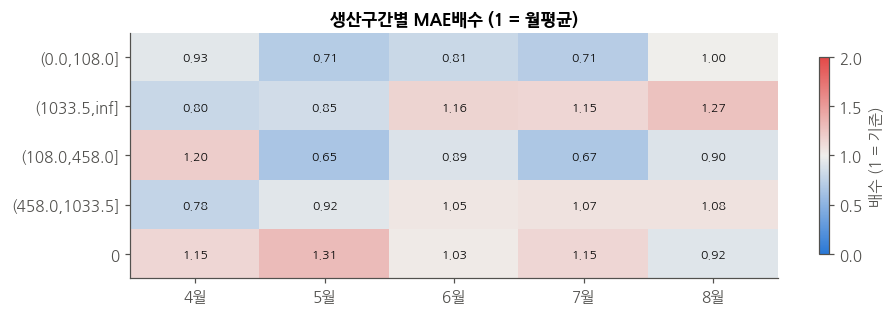

4월 전체 MAE 15.828


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
0,"(0.0,108.0]",115,26,14.739,25.737,12.225,21.957,0.931,0.732,1.173,...,8.696,0.624,1.297,2000,0.706,1.220,2000,0.732,1.173,2000
1,"(1033.5,inf]",135,25,12.718,17.243,10.455,20.000,0.804,0.646,1.007,...,5.185,0.597,1.069,2000,0.617,1.084,2000,0.646,1.007,2000
2,"(108.0,458.0]",109,23,19.029,31.399,16.940,15.367,1.202,0.800,1.655,...,11.927,0.790,1.680,2000,0.778,1.679,2000,0.800,1.655,2000
3,"(458.0,1033.5]",111,24,12.340,20.012,8.798,29.054,0.780,0.592,1.047,...,3.604,0.585,1.049,2000,0.594,1.043,2000,0.592,1.047,2000
4,0,250,29,18.161,31.134,-6.324,34.700,1.147,0.842,1.467,...,22.000,0.720,1.648,2000,0.799,1.557,2000,0.842,1.467,2000


5월 전체 MAE 11.252


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
5,"(0.0,108.0]",100,26,7.986,11.598,1.454,46.250,0.710,0.504,1.015,...,2.000,0.465,1.035,2000,0.466,1.069,2000,0.504,1.015,2000
6,"(1033.5,inf]",134,24,9.548,13.848,3.896,39.925,0.849,0.624,1.209,...,6.716,0.550,1.237,2000,0.573,1.246,2000,0.624,1.209,2000
7,"(108.0,458.0]",112,24,7.336,9.818,2.522,36.607,0.652,0.476,0.903,...,4.464,0.417,0.928,2000,0.443,0.932,2000,0.476,0.903,2000
8,"(458.0,1033.5]",90,23,10.395,20.439,3.793,45.000,0.924,0.573,1.462,...,5.556,0.531,1.573,2000,0.537,1.548,2000,0.573,1.462,2000
9,0,308,27,14.728,32.938,-7.493,28.571,1.309,0.898,1.700,...,13.961,0.888,1.765,2000,0.869,1.824,2000,0.898,1.700,2000


6월 전체 MAE 11.836


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
10,"(0.0,108.0]",123,25,9.607,12.006,-6.913,76.220,0.812,0.675,0.962,...,0.813,0.674,0.991,2000,0.666,0.984,2000,0.675,0.962,2000
11,"(1033.5,inf]",150,24,13.738,16.672,-10.655,79.000,1.161,1.024,1.322,...,2.667,0.987,1.416,2000,1.001,1.405,2000,1.024,1.322,2000
12,"(108.0,458.0]",111,23,10.572,13.521,-9.258,84.685,0.893,0.743,1.073,...,1.802,0.740,1.136,2000,0.728,1.132,2000,0.743,1.073,2000
13,"(458.0,1033.5]",113,26,12.394,15.237,-9.344,80.310,1.047,0.929,1.202,...,0.885,0.868,1.281,2000,0.887,1.261,2000,0.929,1.202,2000
14,0,223,27,12.134,28.840,-11.840,84.417,1.025,0.791,1.411,...,14.798,0.745,1.583,2000,0.746,1.565,2000,0.791,1.411,2000


7월 전체 MAE 12.786


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
15,"(0.0,108.0]",106,24,9.109,11.620,1.160,40.330,0.712,0.592,0.890,...,0.000,0.546,0.952,2000,0.559,0.941,2000,0.592,0.890,2000
16,"(1033.5,inf]",138,21,14.650,17.897,-11.428,80.254,1.146,0.990,1.330,...,0.725,0.939,1.454,2000,0.973,1.382,2000,0.990,1.330,2000
17,"(108.0,458.0]",103,23,8.529,10.961,-2.135,57.282,0.667,0.576,0.806,...,0.000,0.530,0.867,2000,0.549,0.834,2000,0.576,0.806,2000
18,"(458.0,1033.5]",94,22,13.741,16.602,-9.649,76.596,1.075,0.914,1.313,...,0.000,0.855,1.388,2000,0.873,1.372,2000,0.914,1.313,2000
19,0,255,25,14.672,33.838,-12.022,52.255,1.148,0.871,1.451,...,16.078,0.802,1.678,2000,0.831,1.631,2000,0.871,1.451,2000


8월 전체 MAE 8.235


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
20,"(0.0,108.0]",84,19,8.212,13.645,3.152,41.964,0.997,0.723,1.420,...,4.762,0.731,1.418,2000,0.711,1.589,2000,0.723,1.420,2000
21,"(1033.5,inf]",124,18,10.429,13.441,0.421,50.605,1.267,1.036,1.654,...,6.452,1.032,1.634,2000,1.012,1.729,2000,1.036,1.654,2000
22,"(108.0,458.0]",99,20,7.449,9.601,0.753,44.444,0.905,0.743,1.214,...,2.020,0.723,1.170,2000,0.720,1.244,2000,0.743,1.214,2000
23,"(458.0,1033.5]",76,20,8.852,11.665,-0.937,52.961,1.075,0.878,1.456,...,6.579,0.877,1.377,2000,0.862,1.471,2000,0.878,1.456,2000
24,0,361,26,7.571,17.808,-0.952,19.321,0.919,0.758,1.255,...,11.357,0.734,1.190,2000,0.725,1.281,2000,0.758,1.255,2000


In [6]:
production_errors = show_monthly_conditions(["생산구간"])

### 2-1. 생산량 0 상태

- 조건별 MAE배수(히트맵), 1·3·7일 stationary bootstrap 점별 신뢰구간, MSE 수준·형태 분해

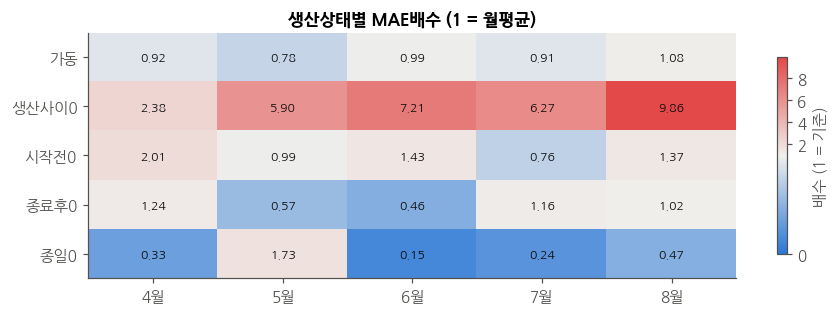

4월 전체 MAE 15.828


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
0,가동,470,26,14.587,23.889,12.001,21.543,0.922,0.770,1.080,...,7.234,0.707,1.162,2000,0.743,1.117,2000,0.770,1.080,2000
1,생산사이0,22,14,37.599,40.317,-33.785,95.455,2.376,1.870,3.040,...,54.545,1.827,3.151,2000,1.825,3.071,2000,1.870,3.040,2000
2,시작전0,51,17,31.770,36.860,0.059,52.941,2.007,1.528,2.420,...,50.980,1.307,2.756,2000,1.416,2.601,2000,1.528,2.420,2000
3,종료후0,81,7,19.622,40.579,-16.247,37.963,1.240,0.234,2.138,...,20.988,0.176,2.982,1999,0.211,2.404,2000,0.234,2.138,2000
4,종일0,96,4,5.243,6.372,4.952,8.333,0.331,0.218,0.468,...,0.000,0.221,0.449,1969,0.211,0.478,1992,0.218,0.468,2000


5월 전체 MAE 11.252


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
5,가동,436,26,8.796,14.170,2.962,41.571,0.782,0.565,1.088,...,4.817,0.517,1.091,2000,0.531,1.110,2000,0.565,1.088,2000
6,생산사이0,12,8,66.398,69.250,-66.398,100.000,5.901,4.301,9.059,...,100.000,3.749,8.539,2000,4.068,8.917,2000,4.301,9.059,2000
7,시작전0,60,11,11.088,18.475,-0.017,19.167,0.985,0.705,1.446,...,15.000,0.616,1.584,2000,0.639,1.517,2000,0.705,1.446,2000
8,종료후0,116,11,6.412,15.875,-0.438,26.724,0.570,0.315,0.971,...,4.310,0.295,1.174,2000,0.303,1.055,2000,0.315,0.971,2000
9,종일0,120,5,19.420,43.482,-12.160,27.917,1.726,0.363,3.097,...,14.167,0.272,3.810,1993,0.310,3.681,2000,0.363,3.097,2000


6월 전체 MAE 11.836


...

7월 전체 MAE 12.786


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
15,가동,441,24,11.695,14.815,-5.853,64.512,0.915,0.789,1.088,...,0.227,0.748,1.162,2000,0.763,1.133,2000,0.789,1.088,2000
16,생산사이0,24,15,80.219,82.275,-80.219,100.000,6.274,5.233,7.867,...,100.000,4.932,8.161,2000,5.007,8.143,2000,5.233,7.867,2000
17,시작전0,37,9,9.673,22.024,-9.172,63.514,0.757,0.582,1.061,...,18.919,0.487,1.485,2000,0.546,1.270,2000,0.582,1.061,2000
18,종료후0,74,7,14.786,38.071,-13.828,61.149,1.156,0.140,2.330,...,13.514,0.158,3.605,2000,0.137,2.943,2000,0.140,2.330,2000
19,종일0,120,5,3.034,5.996,1.852,33.750,0.237,0.118,0.361,...,0.000,0.102,0.505,1995,0.110,0.409,1999,0.118,0.361,2000


8월 전체 MAE 8.235


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
20,가동,383,20,8.860,12.254,0.836,47.585,1.076,0.874,1.423,...,4.961,0.886,1.360,2000,0.863,1.482,2000,0.874,1.423,2000
21,생산사이0,11,7,81.152,82.214,-81.152,100.000,9.855,7.754,14.529,...,100.000,7.891,13.118,2000,7.587,13.852,1995,7.754,14.529,1995
22,시작전0,37,11,11.246,21.602,-8.441,33.108,1.366,0.800,2.330,...,21.622,0.682,3.610,2000,0.628,2.792,1999,0.800,2.330,2000
23,종료후0,49,4,8.399,15.598,-1.074,38.776,1.020,0.172,3.002,...,18.367,0.142,8.264,1967,0.151,3.091,1996,0.172,3.002,1996
24,종일0,264,11,3.837,6.440,3.461,10.417,0.466,0.194,0.715,...,4.924,0.279,0.707,2000,0.234,0.718,2000,0.194,0.715,2000


시간행수                                MAE                              \
month 202104 202105 202106 202107 202108 202104 202105 202106 202107 202108   
생산상태                                                                          
가동       470    436    497    441    383  14.59   8.80  11.70  11.69   8.86   
생산사이0     22     12     17     24     11  37.60  66.40  85.29  80.22  81.15   
시작전0      51     60     43     37     37  31.77  11.09  16.89   9.67  11.25   
종료후0      81    116     67     74     49  19.62   6.41   5.41  14.79   8.40   
종일0       96    120     96    120    264   5.24  19.42   1.74   3.03   3.84   

          편향                             수준오차비중_%                              
month 202104 202105 202106 202107 202108   202104 202105 202106 202107 202108  
생산상태                                                                           
가동     12.00   2.96  -9.12  -5.85   0.84    92.70  80.47  82.39  73.53  67.57  
생산사이0 -33.79 -66.40 -85.29 -80.22 -81.15    94.06  97.16  98.95  98.81  99.10  
시작전0    0.06  -0.02 -16.88  -9.17  -8.44    95.15  71.73  91.88  74.62  93.88  
종료후0  -16.25  -0.44  -5.13 -13.83  -1.07    98.02  96.18  95.56  98.14  94.62  
종일0     4.95 -12.16  -1.26   1.85   3.46    93.41  98.19  66.04  95.55  93.52

In [7]:
state_errors = show_monthly_conditions(["생산상태"])
state_summary = errors.groupby(["생산상태", "month"]).agg(
    시간행수=("row_id", "size"), MAE=("행_MAE", "mean"), 편향=("편향", "mean"),
    수준MSE=("수준MSE", "sum"), 행_MSE=("행_MSE", "sum"),
)
state_summary["수준오차비중_%"] = 100 * state_summary.pop("수준MSE") / state_summary.pop("행_MSE")
display(state_summary.round(2).unstack("month"))

### 3. 평일·주말

- 조건별 MAE배수(히트맵), 1·3·7일 stationary bootstrap 점별 신뢰구간

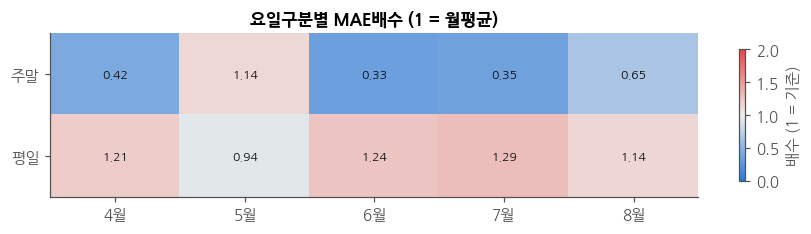

4월 전체 MAE 15.828


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
0,주말,192,8,6.650,12.721,0.736,21.094,0.420,0.315,0.521,...,3.646,0.250,0.649,2000,0.288,0.566,1999,0.315,0.521,2000
1,평일,528,22,19.165,30.135,7.420,27.936,1.211,1.114,1.335,...,15.530,1.076,1.415,2000,1.085,1.382,2000,1.114,1.335,2000


5월 전체 MAE 11.252


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
2,주말,240,10,12.784,31.944,-6.008,29.271,1.136,0.549,1.730,...,9.167,0.463,1.885,2000,0.488,1.887,2000,0.549,1.730,2000
3,평일,504,21,10.523,18.729,0.844,39.484,0.935,0.673,1.269,...,8.333,0.627,1.264,2000,0.643,1.281,2000,0.673,1.269,2000


6월 전체 MAE 11.836


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
4,주말,192,8,3.948,9.745,-3.224,79.688,0.334,0.222,0.446,...,1.042,0.155,0.515,2000,0.197,0.472,2000,0.222,0.446,2000
5,평일,528,22,14.705,22.747,-12.412,81.866,1.242,1.134,1.385,...,7.386,1.094,1.497,2000,1.100,1.451,2000,1.134,1.385,2000


7월 전체 MAE 12.786


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
6,주말,216,9,4.516,10.024,0.770,39.699,0.353,0.255,0.450,...,1.852,0.194,0.536,2000,0.232,0.483,2000,0.255,0.450,2000
7,평일,480,20,16.507,27.654,-12.111,69.167,1.291,1.181,1.428,...,7.917,1.120,1.568,2000,1.139,1.504,2000,1.181,1.428,2000


8월 전체 MAE 8.235


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
8,주말,216,9,5.333,8.938,2.916,22.338,0.648,0.267,1.165,...,9.722,0.312,0.988,1999,0.276,1.127,2000,0.267,1.165,2000
9,평일,528,22,9.421,17.119,-1.238,38.589,1.144,0.933,1.317,...,7.386,1.005,1.329,2000,0.952,1.352,2000,0.933,1.317,2000


In [8]:
weekday_errors = show_monthly_conditions(["요일구분"])

### 4. 시간대

- 고정 6시간 구간별 MAE배수와 표본 수. 1·3·7일 블록의 점별 95% 구간을 함께 확인.

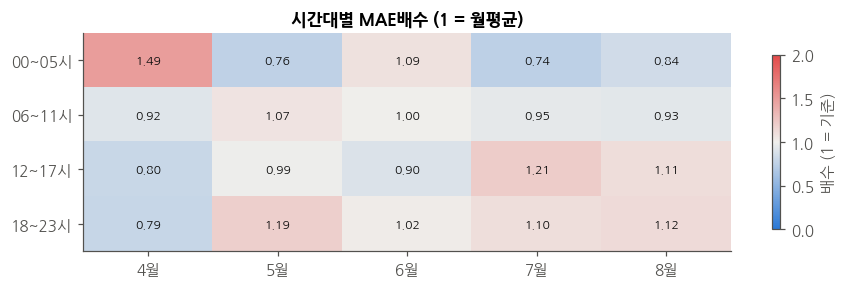

4월 전체 MAE 15.828


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
0,00~05시,180,30,23.610,35.247,10.931,29.722,1.492,1.228,1.766,...,26.667,1.085,1.879,2000,1.201,1.801,2000,1.228,1.766,2000
1,06~11시,180,30,14.557,26.985,4.453,27.083,0.920,0.853,0.981,...,9.444,0.834,1.003,2000,0.839,0.993,2000,0.853,0.981,2000
2,12~17시,180,30,12.624,21.127,4.773,21.944,0.798,0.630,0.970,...,3.889,0.584,1.021,2000,0.593,0.983,2000,0.630,0.970,2000
3,18~23시,180,30,12.520,20.482,2.395,25.694,0.791,0.712,0.875,...,9.444,0.616,0.967,2000,0.688,0.896,2000,0.712,0.875,2000


5월 전체 MAE 11.252


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
4,00~05시,186,31,8.520,15.590,-0.460,31.989,0.757,0.530,1.057,...,5.914,0.440,1.154,2000,0.483,1.120,2000,0.530,1.057,2000
5,06~11시,186,31,12.018,28.030,-1.279,43.548,1.068,0.914,1.204,...,9.140,0.842,1.260,2000,0.859,1.245,2000,0.914,1.204,2000
6,12~17시,186,31,11.086,23.024,-0.098,28.629,0.985,0.753,1.168,...,5.914,0.762,1.179,2000,0.746,1.190,2000,0.753,1.168,2000
7,18~23시,186,31,13.385,26.613,-3.629,40.591,1.190,1.045,1.333,...,13.441,0.942,1.388,2000,0.999,1.360,2000,1.045,1.333,2000


6월 전체 MAE 11.836


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
8,00~05시,180,30,12.846,23.657,-11.916,87.222,1.085,0.892,1.276,...,10.000,0.821,1.355,2000,0.861,1.319,2000,0.892,1.276,2000
9,06~11시,180,30,11.796,17.975,-9.712,82.500,0.997,0.887,1.109,...,5.000,0.883,1.121,2000,0.878,1.116,2000,0.887,1.109,2000
10,12~17시,180,30,10.613,16.658,-8.563,77.917,0.897,0.814,0.985,...,3.333,0.749,1.051,2000,0.791,1.029,2000,0.814,0.985,2000
11,18~23시,180,30,12.090,21.421,-9.656,77.500,1.021,0.913,1.138,...,4.444,0.859,1.190,2000,0.876,1.158,2000,0.913,1.138,2000


7월 전체 MAE 12.786


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
12,00~05시,174,29,9.516,17.463,-2.689,45.977,0.744,0.600,0.946,...,6.322,0.515,1.001,2000,0.557,0.987,2000,0.600,0.946,2000
13,06~11시,174,29,12.122,19.005,-9.429,71.121,0.948,0.854,1.062,...,4.598,0.819,1.094,2000,0.837,1.085,2000,0.854,1.062,2000
14,12~17시,174,29,15.436,27.644,-10.907,72.126,1.207,1.077,1.366,...,6.322,1.045,1.390,2000,1.049,1.393,2000,1.077,1.366,2000
15,18~23시,174,29,14.068,28.355,-9.427,50.862,1.100,0.854,1.301,...,6.897,0.818,1.397,2000,0.824,1.345,2000,0.854,1.301,2000


8월 전체 MAE 8.235


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
16,00~05시,186,31,6.924,12.586,1.193,27.151,0.841,0.697,1.011,...,8.065,0.621,1.095,2000,0.660,1.043,2000,0.697,1.011,2000
17,06~11시,186,31,7.664,12.111,1.711,34.274,0.931,0.822,1.080,...,7.527,0.797,1.087,2000,0.808,1.088,2000,0.822,1.080,2000
18,12~17시,186,31,9.110,16.215,-1.659,39.382,1.106,0.879,1.344,...,7.527,0.871,1.327,2000,0.875,1.380,2000,0.879,1.344,2000
19,18~23시,186,31,9.240,18.886,-1.372,34.677,1.122,0.958,1.274,...,9.140,0.886,1.354,2000,0.910,1.305,2000,0.958,1.274,2000


In [9]:
time_errors = show_monthly_conditions(["시간대"])

### 5. 기온 구간

- 사분위 구간화, 조건별 MAE배수(히트맵), 1·3·7일 stationary bootstrap 점별 신뢰구간

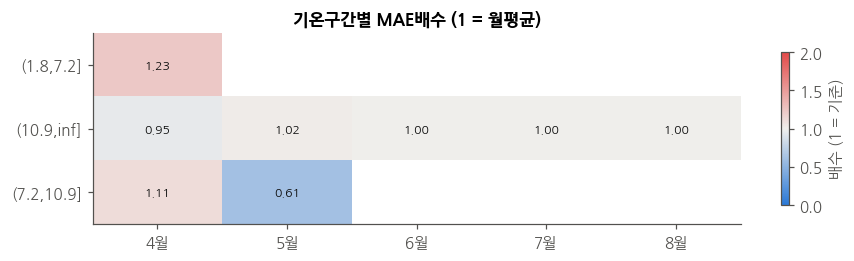

4월 전체 MAE 15.828


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
0,"(1.8,7.2]",47,9,19.482,28.041,8.983,29.787,1.231,0.879,1.827,...,19.149,0.599,1.999,2000,0.751,1.912,2000,0.879,1.827,2000
1,"(10.9,inf]",545,30,15.104,26.187,4.650,25.642,0.954,0.869,1.013,...,10.459,0.809,1.063,2000,0.848,1.035,2000,0.869,1.013,2000
2,"(7.2,10.9]",128,20,17.569,27.930,8.616,26.758,1.110,0.874,1.423,...,17.969,0.705,1.585,2000,0.817,1.495,2000,0.874,1.423,2000


5월 전체 MAE 11.252


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
3,"(10.9,inf]",713,31,11.442,24.218,-1.609,37.132,1.017,0.999,1.041,...,8.836,0.988,1.050,2000,0.995,1.047,2000,0.999,1.041,2000
4,"(7.2,10.9]",31,5,6.879,10.611,4.213,14.516,0.611,0.269,1.047,...,3.226,0.156,1.333,1993,0.235,1.241,1948,0.269,1.047,1900


6월 전체 MAE 11.836


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
5,"(10.9,inf]",720,30,11.836,20.119,-9.962,81.285,1.0,1.0,1.0,...,5.694,1.0,1.0,2000,1.0,1.0,2000,1.0,1.0,2000


7월 전체 MAE 12.786


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
6,"(10.9,inf]",696,29,12.786,23.635,-8.113,60.022,1.0,1.0,1.0,...,6.034,1.0,1.0,2000,1.0,1.0,2000,1.0,1.0,2000


8월 전체 MAE 8.235


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
7,"(10.9,inf]",744,31,8.235,15.205,-0.032,33.871,1.0,1.0,1.0,...,8.065,1.0,1.0,2000,1.0,1.0,2000,1.0,1.0,2000


In [10]:
temperature_errors = show_monthly_conditions(["기온구간"])

### 5-1. 생산조건 층 내 기온

- 층화 비교(월·요일구분·시간대·생산구간 층 평균 대비 MAE배수)

month,202104,202105
기온구간,,
"(1.8,7.2]",0.87,NaN
"(10.9,inf]",1.03,1.04
"(7.2,10.9]",0.94,0.62


month,202104,202105
기온구간,,
"(1.8,7.2]",46,0
"(10.9,inf]",486,272
"(7.2,10.9]",128,31


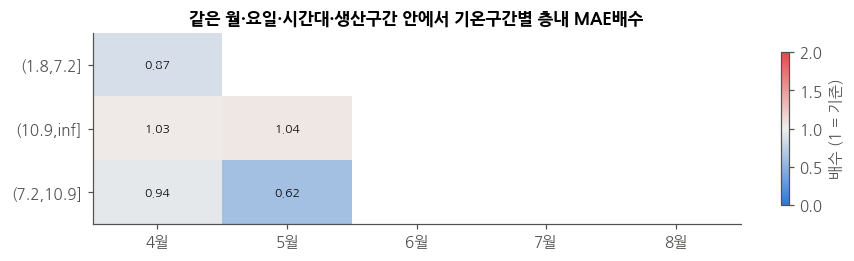

In [11]:
# 기온구간별 MAE배수(층 = 월·요일구분·시간대·생산구간, 층 평균 대비)
strata = ["month", "요일구분", "시간대", "생산구간"]
errors["층내MAE배수"] = errors["행_MAE"] / errors.groupby(strata)["행_MAE"].transform("mean").replace(0, np.nan)
mixed = errors.groupby(strata)["기온구간"].transform("nunique").gt(1)  # 기온구간이 2개 이상 섞인 층만
within_temperature = errors.loc[mixed].groupby(["기온구간", "month"])["층내MAE배수"].agg(["mean", "size"])
display(within_temperature["mean"].unstack("month").round(2))
display(within_temperature["size"].unstack("month").fillna(0).astype(int))

ratio_heatmap(within_temperature["mean"].unstack("month").reindex(columns=MONTHS),
              "같은 월·요일·시간대·생산구간 안에서 기온구간별 층내 MAE배수")

### 5-2. 구간화에 의존하지 않는 오차와 입력 범위 확인

- 생산량·기온은 연속값 그대로 월별 잔차를 표시한다. 6시간 구간 비교와 별도로 24개 시간별 MAE·편향·표본 수를 확인한다.
- 기준기간과 월별 입력 범위·표본 수를 함께 표시한다. 계절별 기온 범위가 겹치지 않으면 기온 효과와 월 효과를 분리할 수 없으며, 산점도는 인과효과를 뜻하지 않는다.


,기간,변수,표본수,최소,25분위,중앙값,75분위,최대
0,기준기간_1~3월,생산량,2160,0.0,0.0,0.0,431.25,9830.0
1,기준기간_1~3월,기온,2160,-12.0,1.8,7.2,10.90,23.6
2,202104,생산량,720,0.0,0.0,102.0,825.00,6290.0
3,202104,기온,720,3.3,11.1,13.9,16.32,24.8
4,202105,생산량,744,0.0,0.0,50.5,674.00,6557.0
5,202105,기온,744,7.6,14.9,17.3,20.70,29.0
6,202106,생산량,720,0.0,0.0,131.5,894.25,6234.0
7,202106,기온,720,14.4,19.6,21.1,23.60,29.2
8,202107,생산량,696,0.0,0.0,91.5,792.75,6579.0
9,202107,기온,696,19.3,23.6,25.4,28.22,33.2


시간수  날짜수     MAE      편향
month  시간                          
202104 0    30   30  13.095   8.937
       1    30   30  26.139  10.140
       2    30   30  27.422  15.130
       3    30   30  27.296   8.284
       4    30   30  23.459  15.592
...        ...  ...     ...     ...
202108 19   31   31   8.609  -0.831
       20   31   31  12.292  -4.991
       21   31   31   7.467  -0.446
       22   31   31   8.711  -1.814
       23   31   31   7.685  -0.078

[120 rows x 4 columns]

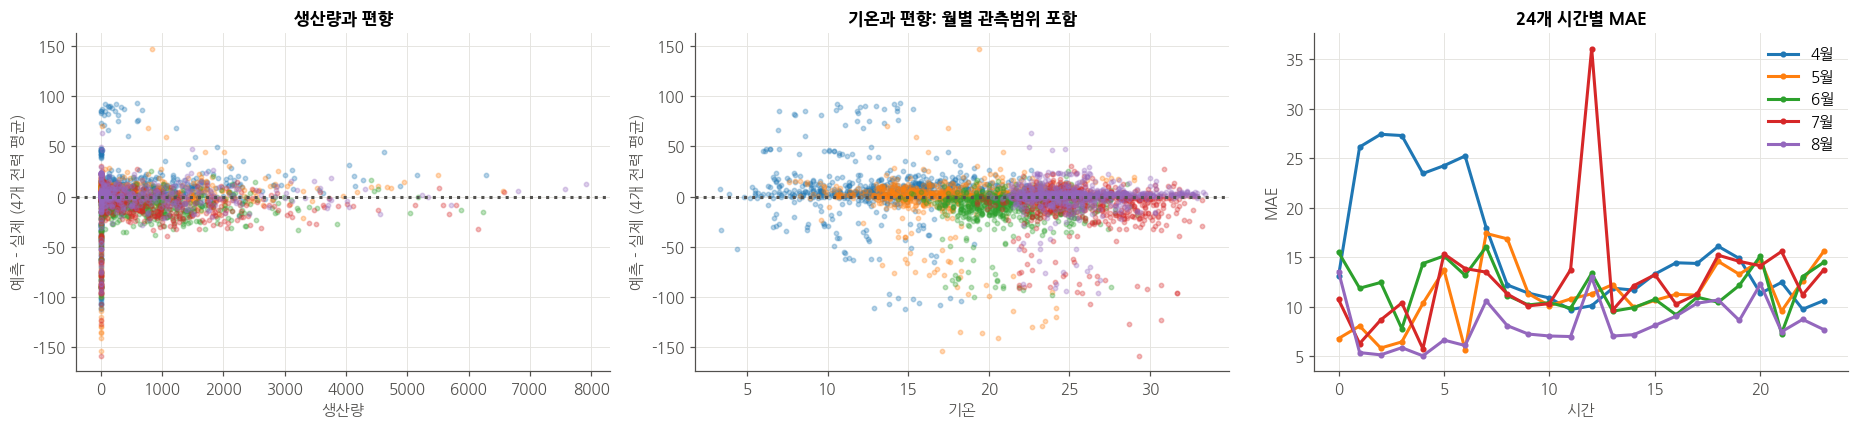

In [12]:
support_rows = []
for name, frame in [("기준기간_1~3월", reference), *list(errors.groupby("month"))]:
    for feature in ["생산량", "기온"]:
        values = frame[feature]
        support_rows.append({"기간": name, "변수": feature, "표본수": values.notna().sum(),
                             "최소": values.min(), "25분위": values.quantile(.25),
                             "중앙값": values.median(), "75분위": values.quantile(.75), "최대": values.max()})
continuous_support = pd.DataFrame(support_rows)
hourly_errors = errors.groupby(["month", "시간"]).agg(시간수=("행_MAE", "size"), 날짜수=("날짜", "nunique"),
                                                       MAE=("행_MAE", "mean"), 편향=("편향", "mean"))
display(continuous_support.round(2))
display(hourly_errors.round(3))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for month, part in errors.groupby("month"):
    label = f"{month % 100}월"
    axes[0].scatter(part["생산량"], part["편향"], s=8, alpha=.3, label=label)
    axes[1].scatter(part["기온"], part["편향"], s=8, alpha=.3, label=label)
    axes[2].plot(part.groupby("시간")["행_MAE"].mean(), marker="o", ms=3, label=label)
for ax, xlabel in zip(axes[:2], ["생산량", "기온"]):
    ax.axhline(0, color=MUTED, ls=":")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("예측 - 실제 (4개 전력 평균)")
axes[0].set_title("생산량과 편향")
axes[1].set_title("기온과 편향: 월별 관측범위 포함")
axes[2].set_title("24개 시간별 MAE")
axes[2].set_xlabel("시간")
axes[2].set_ylabel("MAE")
axes[2].legend()
plt.tight_layout()
plt.show()


### 6. 복합 생산조건

- 조건별 MAE배수(히트맵), 1·3·7일 stationary bootstrap 점별 신뢰구간, 월 오차 기여 비중

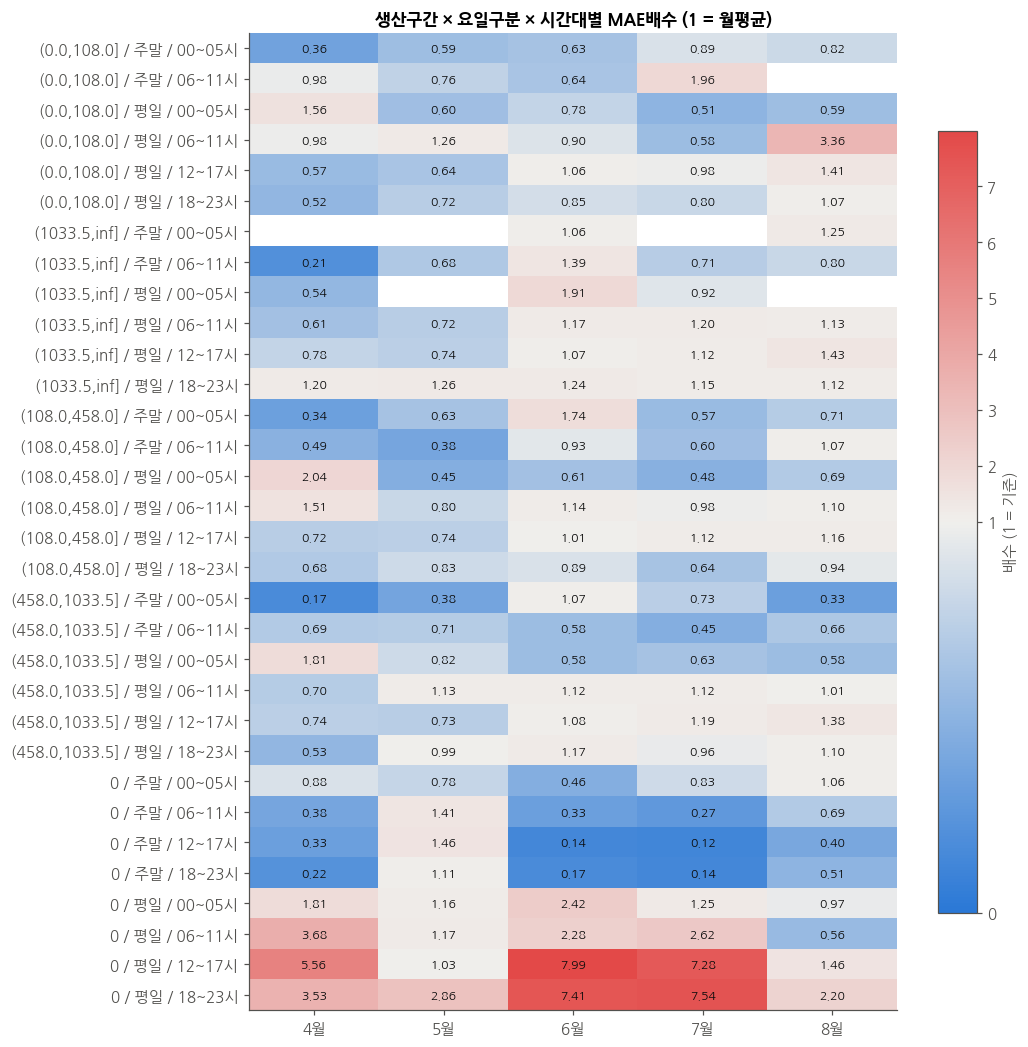

4월 전체 MAE 15.828


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
0,"(0.0,108.0] / 주말 / 00~05시",5,3,5.737,7.664,2.871,40.000,0.362,0.225,0.705,...,0.000,0.225,0.753,1916,0.221,0.730,1965,0.225,0.705,1978
1,"(0.0,108.0] / 주말 / 06~11시",2,2,15.452,17.486,-15.132,87.500,0.976,0.558,1.626,...,0.000,0.556,1.605,1752,0.535,1.626,1798,0.558,1.626,1862
2,"(0.0,108.0] / 평일 / 00~05시",41,17,24.612,38.746,23.767,11.585,1.555,1.009,2.295,...,21.951,0.784,2.526,2000,0.964,2.410,2000,1.009,2.295,2000
3,"(0.0,108.0] / 평일 / 06~11시",9,9,15.541,29.473,12.962,36.111,0.982,0.376,1.742,...,11.111,0.289,2.342,2000,0.326,1.858,2000,0.376,1.742,2000
4,"(0.0,108.0] / 평일 / 12~17시",7,7,8.957,10.125,5.500,28.571,0.566,0.386,0.873,...,0.000,0.352,0.847,1999,0.374,0.875,1998,0.386,0.873,1999
5,"(0.0,108.0] / 평일 / 18~23시",51,19,8.308,10.079,5.728,22.549,0.525,0.412,0.678,...,0.000,0.399,0.710,2000,0.405,0.697,2000,0.412,0.678,2000
6,"(1033.5,inf] / 주말 / 06~11시",3,3,3.337,4.291,-0.391,50.000,0.211,0.111,0.313,...,0.000,0.122,0.339,1916,0.116,0.331,1965,0.111,0.313,1978
7,"(1033.5,inf] / 평일 / 00~05시",1,1,8.478,10.714,4.522,25.000,0.536,0.420,0.660,...,0.000,0.419,0.707,1247,0.409,0.694,1312,0.420,0.660,1469
8,"(1033.5,inf] / 평일 / 06~11시",40,22,9.690,15.105,8.237,19.375,0.612,0.440,0.777,...,2.500,0.428,0.905,2000,0.436,0.819,2000,0.440,0.777,2000
9,"(1033.5,inf] / 평일 / 12~17시",63,21,12.363,15.323,10.687,16.270,0.781,0.604,1.022,...,1.587,0.572,1.080,2000,0.573,1.106,2000,0.604,1.022,2000


5월 전체 MAE 11.252


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
31,"(0.0,108.0] / 주말 / 00~05시",14,5,6.602,8.236,5.046,25.000,0.587,0.352,0.985,...,0.000,0.340,1.002,1988,0.343,1.022,1998,0.352,0.985,2000
32,"(0.0,108.0] / 주말 / 06~11시",1,1,8.593,8.780,8.593,0.000,0.764,0.560,1.055,...,0.000,0.507,1.047,1313,0.538,1.086,1316,0.560,1.055,1388
33,"(0.0,108.0] / 평일 / 00~05시",30,12,6.736,8.267,-0.257,49.167,0.599,0.414,0.899,...,0.000,0.392,0.868,2000,0.398,0.911,2000,0.414,0.899,2000
34,"(0.0,108.0] / 평일 / 06~11시",9,8,14.232,25.386,4.143,66.667,1.265,0.476,2.378,...,11.111,0.425,3.067,2000,0.424,2.846,2000,0.476,2.378,2000
35,"(0.0,108.0] / 평일 / 12~17시",7,7,7.226,8.571,-0.226,57.143,0.642,0.448,0.924,...,0.000,0.385,0.979,1999,0.402,0.978,1999,0.448,0.924,2000
36,"(0.0,108.0] / 평일 / 18~23시",39,18,8.123,10.204,0.978,46.154,0.722,0.528,1.053,...,2.564,0.462,1.056,2000,0.481,1.094,2000,0.528,1.053,2000
37,"(1033.5,inf] / 주말 / 06~11시",4,4,7.632,10.029,-4.762,62.500,0.678,0.307,1.224,...,0.000,0.295,1.174,1963,0.294,1.271,1988,0.307,1.224,1995
38,"(1033.5,inf] / 평일 / 06~11시",43,20,8.135,14.250,1.315,53.488,0.723,0.436,1.148,...,4.651,0.423,1.233,2000,0.431,1.211,2000,0.436,1.148,2000
39,"(1033.5,inf] / 평일 / 12~17시",57,19,8.333,10.399,3.757,32.895,0.741,0.559,1.070,...,1.754,0.477,1.076,2000,0.520,1.098,2000,0.559,1.070,2000
40,"(1033.5,inf] / 평일 / 18~23시",30,18,14.136,18.617,9.014,30.833,1.256,0.921,1.746,...,20.000,0.728,2.079,2000,0.804,1.895,2000,0.921,1.746,2000


6월 전체 MAE 11.836


...

,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
89,0 / 평일 / 00~05시,41,16,28.694,44.471,-28.690,98.780,2.424,1.556,3.518,...,41.463,1.200,4.628,2000,1.391,4.050,2000,1.556,3.518,2000
70,"(1033.5,inf] / 평일 / 06~11시",55,22,13.897,16.827,-10.858,80.455,1.174,1.010,1.353,...,3.636,0.983,1.455,2000,0.995,1.451,2000,1.010,1.353,2000
71,"(1033.5,inf] / 평일 / 12~17시",57,22,12.716,15.300,-10.252,78.947,1.074,0.932,1.257,...,1.754,0.879,1.346,2000,0.893,1.345,2000,0.932,1.257,2000
92,0 / 평일 / 18~23시,7,7,87.710,88.872,-87.710,100.000,7.410,6.474,8.757,...,100.000,6.289,9.189,2000,6.254,9.080,2000,6.474,8.757,2000
83,"(458.0,1033.5] / 평일 / 12~17시",46,20,12.806,15.480,-9.845,80.978,1.082,0.924,1.287,...,0.000,0.863,1.370,2000,0.887,1.362,2000,0.924,1.287,2000


7월 오차 기여 상위 5


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
123,0 / 평일 / 18~23시,12,6,96.467,99.578,-96.467,100.000,7.545,6.358,9.249,...,100.000,5.945,9.747,2000,5.952,9.844,1997,6.358,9.249,1998
122,0 / 평일 / 12~17시,11,10,93.035,94.740,-93.035,100.000,7.276,6.220,8.990,...,100.000,5.845,9.298,2000,5.879,9.398,2000,6.220,8.990,2000
102,"(1033.5,inf] / 평일 / 12~17시",57,20,14.320,17.448,-8.817,73.684,1.120,0.969,1.319,...,0.000,0.898,1.437,2000,0.929,1.376,2000,0.969,1.319,2000
101,"(1033.5,inf] / 평일 / 06~11시",46,19,15.298,18.655,-13.711,85.326,1.197,0.875,1.435,...,2.174,0.920,1.564,2000,0.882,1.496,2000,0.875,1.435,2000
113,"(458.0,1033.5] / 평일 / 06~11시",48,19,14.358,16.921,-13.229,89.062,1.123,0.891,1.465,...,0.000,0.857,1.512,2000,0.876,1.480,2000,0.891,1.465,2000


8월 오차 기여 상위 5


,조건,시간행수,날짜수,MAE,RMSE,편향,과소예측률_%,MAE배수,배수하한,배수상한,...,큰오차율_%,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일
132,"(1033.5,inf] / 평일 / 12~17시",57,17,11.793,15.423,0.710,50.000,1.432,1.154,1.844,...,8.772,1.130,1.910,2000,1.118,1.983,2000,1.154,1.844,2000
153,0 / 평일 / 18~23시,37,10,18.124,36.967,-13.827,25.676,2.201,0.716,10.380,...,18.919,0.944,4.834,2000,0.722,9.714,1999,0.716,10.380,2000
150,0 / 평일 / 00~05시,61,16,7.960,17.750,-4.034,19.262,0.967,0.596,1.784,...,11.475,0.539,1.838,2000,0.484,1.901,2000,0.596,1.784,2000
152,0 / 평일 / 12~17시,34,8,12.040,27.658,-6.744,17.647,1.462,0.430,8.991,...,11.765,0.419,3.395,1999,0.419,8.799,1998,0.430,8.991,1993
131,"(1033.5,inf] / 평일 / 06~11시",41,17,9.343,11.520,1.118,48.780,1.135,0.893,1.550,...,7.317,0.881,1.510,2000,0.861,1.638,2000,0.893,1.550,2000


In [13]:
joint_errors = show_monthly_conditions(["생산구간", "요일구분", "시간대"])
for month in MONTHS:
    part = joint_errors.loc[joint_errors["month"].eq(month)]
    print(f"{month % 100}월 오차 기여 상위 5")
    display(part.sort_values("월오차비중_%", ascending=False).head(5)[columns].round(3))

### 7. 조건별 월간 일관성

- 모든 조건의 효과 크기·관측월수·월평균 초과월수 보고. 월 5개에 대한 부호검정 및 유의성 선별은 하지 않음.

In [14]:
condition_month_matrix = joint_errors.pivot(index="조건", columns="month", values="MAE배수").reindex(columns=MONTHS)
above = condition_month_matrix.gt(1).sum(axis=1)
observed = condition_month_matrix.notna().sum(axis=1)
condition_consistency = condition_month_matrix.assign(초과월수=above, 관측월수=observed)
display(condition_consistency.round(3))
condition_errors = pd.concat(condition_tables, names=["분석축", "번호"]).reset_index(level="분석축").reset_index(drop=True)

month,202104,202105,202106,202107,202108,초과월수,관측월수
조건,,,,,,,
"(0.0,108.0] / 주말 / 00~05시",0.362,0.587,0.632,0.890,0.816,0,5
"(0.0,108.0] / 주말 / 06~11시",0.976,0.764,0.645,1.964,NaN,1,4
"(0.0,108.0] / 평일 / 00~05시",1.555,0.599,0.780,0.514,0.589,1,5
"(0.0,108.0] / 평일 / 06~11시",0.982,1.265,0.898,0.583,3.356,2,5
"(0.0,108.0] / 평일 / 12~17시",0.566,0.642,1.062,0.983,1.410,2,5
"(0.0,108.0] / 평일 / 18~23시",0.525,0.722,0.853,0.798,1.073,1,5
"(1033.5,inf] / 주말 / 00~05시",NaN,NaN,1.063,NaN,1.249,2,2
"(1033.5,inf] / 주말 / 06~11시",0.211,0.678,1.389,0.715,0.802,1,5
"(1033.5,inf] / 평일 / 00~05시",0.536,NaN,1.910,0.917,NaN,1,3


### 8. 월별 큰 오차 사례

- 행_MAE 상위 10개 추출

In [15]:
# 사례 기준: 행_MAE(4개 출력 절대오차 평균)
worst_rows = (errors.sort_values(["month", "행_MAE"], ascending=[True, False])
             .groupby("month", sort=False).head(10))
case_columns = ["row_id", "날짜", "시간", "생산량", "기온", "요일구분", "행_MAE", "편향",
                *POWER, *[f"pred_{p}" for p in POWER]]
for month in MONTHS:
    print(f"{month % 100}월 행_MAE 상위 10")
    display(worst_rows.loc[worst_rows["month"].eq(month), case_columns].round(3))

# 결과 변수: condition_errors(전체 조건), monthly(월별 요약),
# condition_month_matrix(월별 비교), errors / worst_rows(행별)

4월 행_MAE 상위 10


,row_id,날짜,시간,생산량,기온,요일구분,행_MAE,편향,15분,30분,45분,60분,pred_15분,pred_30분,pred_45분,pred_60분
35,2195,20210402,11,0,14.8,평일,112.697,-112.697,178,169,170,173,58.700,59.769,60.713,60.031
32,2192,20210402,8,0,12.9,평일,111.128,-111.128,162,181,167,175,59.593,60.219,60.708,59.970
38,2198,20210402,14,0,17.0,평일,108.161,-108.161,161,163,161,180,56.773,58.311,58.973,58.299
33,2193,20210402,9,0,13.8,평일,107.478,-107.478,169,155,177,172,61.152,61.054,61.101,59.783
37,2197,20210402,13,0,15.7,평일,106.490,-106.490,170,166,165,160,58.074,58.599,59.584,58.781
40,2200,20210402,16,0,18.3,평일,103.834,-103.834,161,164,162,157,55.984,57.600,58.070,57.008
42,2202,20210402,18,0,15.3,평일,102.683,-102.683,150,169,169,162,59.142,59.973,60.302,59.853
39,2199,20210402,15,0,17.6,평일,101.561,-101.561,133,173,177,153,56.650,57.607,57.821,57.677
34,2194,20210402,10,0,14.4,평일,100.962,-100.962,129,170,169,174,58.956,59.722,60.275,59.199
43,2203,20210402,19,0,13.8,평일,97.118,-97.118,159,164,172,138,60.519,61.229,61.756,61.022


5월 행_MAE 상위 10


,row_id,날짜,시간,생산량,기온,요일구분,행_MAE,편향,15분,30분,45분,60분,pred_15분,pred_30분,pred_45분,pred_60분
920,3080,20210509,8,0,17.1,주말,154.583,-154.583,160,180,182,184,23.379,21.742,21.109,21.439
1160,3320,20210519,8,841,19.4,평일,147.769,147.769,20,20,20,23,156.914,174.047,169.886,173.228
923,3083,20210509,11,0,20.6,주말,140.873,-140.873,173,157,172,153,24.387,22.706,22.098,22.318
922,3082,20210509,10,0,19.6,주말,135.918,-135.918,128,169,163,168,20.406,20.677,20.699,22.546
921,3081,20210509,9,0,18.2,주말,135.021,-135.021,164,163,156,149,21.203,23.025,24.701,22.990
925,3085,20210509,13,0,22.7,주말,130.127,-130.127,155,158,158,159,30.992,26.611,26.323,25.564
930,3090,20210509,18,0,23.3,주말,128.784,-128.784,153,165,158,160,34.583,30.124,27.554,28.605
926,3086,20210509,14,0,23.5,주말,124.704,-124.704,149,152,163,153,36.278,30.478,25.401,26.028
928,3088,20210509,16,0,24.2,주말,120.614,-120.614,147,151,155,157,37.038,32.166,28.592,29.748
931,3091,20210509,19,0,21.5,주말,114.117,-114.117,155,147,147,117,27.517,26.582,28.589,26.844


6월 행_MAE 상위 10


,row_id,날짜,시간,생산량,기온,요일구분,행_MAE,편향,15분,30분,45분,60분,pred_15분,pred_30분,pred_45분,pred_60분
2038,4198,20210624,22,0,19.1,평일,99.871,-99.871,104,124,122,135,21.916,21.626,21.547,20.427
1788,3948,20210614,12,0,23.9,평일,98.388,-98.388,123,104,108,140,20.074,20.944,20.497,19.935
2166,4326,20210630,6,0,22.1,평일,93.555,-93.555,113,111,115,118,20.068,20.281,20.981,21.451
1798,3958,20210614,22,0,20.9,평일,91.422,-91.422,100,108,109,129,20.098,20.469,19.869,19.878
1668,3828,20210609,12,0,27.6,평일,90.751,-90.751,119,102,96,122,18.696,18.425,18.371,20.502
2132,4292,20210628,20,0,21.9,평일,90.681,-90.681,110,113,111,113,21.384,21.260,20.935,20.699
1508,3668,20210602,20,0,18.9,평일,90.633,-90.633,104,118,114,114,21.144,22.650,22.109,21.563
1801,3961,20210615,1,0,20.4,평일,90.414,-90.414,100,110,115,116,19.926,20.404,19.665,19.350
1970,4130,20210622,2,0,17.3,평일,90.210,-90.210,118,110,103,120,21.308,22.635,23.125,23.090
1708,3868,20210611,4,0,20.9,평일,89.621,-89.621,113,114,110,108,21.323,21.144,21.189,22.860


7월 행_MAE 상위 10


,row_id,날짜,시간,생산량,기온,요일구분,행_MAE,편향,15분,30분,45분,60분,pred_15분,pred_30분,pred_45분,pred_60분
2850,5058,20210730,18,0,29.3,평일,159.059,-159.059,190,177,181,185,24.206,24.346,23.699,24.514
2851,5059,20210730,19,0,28.7,평일,126.945,-126.945,175,152,153,124,24.104,23.901,23.929,24.286
2849,5057,20210730,17,0,30.7,평일,123.140,-123.140,123,106,169,190,23.563,23.621,24.296,23.959
2636,4844,20210721,20,0,26.3,평일,107.104,-107.104,126,138,131,128,23.144,24.110,23.854,23.474
2604,4812,20210720,12,0,31.7,평일,96.670,-96.670,142,121,109,112,24.394,24.157,24.096,24.672
2844,5052,20210730,12,0,31.7,평일,96.408,-96.408,145,111,111,116,23.845,23.915,24.437,25.170
2661,4869,20210722,21,0,25.8,평일,96.236,-96.236,119,119,123,118,23.655,23.333,23.810,23.257
2364,4524,20210708,12,0,25.5,평일,95.640,-95.640,131,112,116,120,23.987,23.550,24.450,24.453
2580,4788,20210719,12,0,29.8,평일,92.480,-92.480,134,111,111,113,25.329,24.463,24.700,24.586
2375,4535,20210708,23,0,21.9,평일,90.867,-90.867,119,115,116,103,23.637,22.299,21.928,21.668


8월 행_MAE 상위 10


,row_id,날짜,시간,생산량,기온,요일구분,행_MAE,편향,15분,30분,45분,60분,pred_15분,pred_30분,pred_45분,pred_60분
3452,5660,20210824,20,0,26.8,평일,96.730,-96.730,117,122,125,120,24.157,25.264,23.993,23.667
3188,5396,20210813,20,0,24.8,평일,94.026,-94.026,106,113,122,125,22.897,21.663,22.830,22.504
3166,5374,20210812,22,0,24.1,평일,90.891,-90.891,109,110,121,122,24.980,24.936,25.072,23.448
3276,5484,20210817,12,0,22.1,평일,87.658,-87.658,109,98,100,134,22.333,22.319,22.596,23.122
3165,5373,20210812,21,0,24.2,평일,87.355,-87.355,110,113,114,110,24.529,23.724,24.744,24.583
3108,5316,20210810,12,0,26.9,평일,83.572,-83.572,119,100,100,110,23.522,23.514,23.628,24.049
3119,5327,20210810,23,0,23.5,평일,76.604,-76.604,103,101,109,84,22.147,22.524,23.200,22.713
3257,5465,20210816,17,0,24.6,평일,75.441,-75.441,105,99,99,95,23.787,23.700,24.039,24.711
3090,5298,20210809,18,0,26.1,평일,73.897,-73.897,103,100,96,94,24.349,24.300,24.439,24.323
3252,5460,20210816,12,0,26.3,평일,70.570,-70.570,107,91,88,100,25.996,26.188,25.578,25.958


### 8-1. 날짜 집중도·학습 전력곡선 중복

- 날짜별 오차 기여 비중, 곡선 완전일치 비교

월오차비중_%
month  날짜               
202104 20210402    12.66
       20210407     7.14
       20210420     6.80
202105 20210509    22.43
       20210519     4.68
       20210514     4.49
202106 20210618     5.80
       20210614     5.75
       20210625     5.69
202107 20210730    13.17
       20210709     7.43
       20210723     5.93
202108 20210816     8.42
       20210813     6.84
       20210809     6.35

month,202104,202105,202106,202107,202108
조건,,,,,
"(0.0,108.0] / 주말 / 00~05시",46.1,23.6,42.2,33.1,37.6
"(0.0,108.0] / 주말 / 06~11시",65.9,100.0,79.7,100.0,NaN
"(0.0,108.0] / 평일 / 00~05시",24.4,16.5,12.8,22.4,15.6
"(0.0,108.0] / 평일 / 06~11시",60.7,55.0,38.7,18.3,46.0
"(0.0,108.0] / 평일 / 12~17시",20.4,20.3,32.7,38.3,47.6
"(0.0,108.0] / 평일 / 18~23시",8.2,16.5,16.9,14.7,27.1
"(1033.5,inf] / 주말 / 00~05시",NaN,NaN,100.0,NaN,100.0
"(1033.5,inf] / 주말 / 06~11시",47.7,36.2,100.0,100.0,100.0
"(1033.5,inf] / 평일 / 00~05시",100.0,NaN,100.0,82.9,NaN


날짜수            MAE             편향        
학습곡선    처음 봄 학습에 있음    처음 봄  학습에 있음   처음 봄  학습에 있음
month                                             
202104  30.0    NaN  15.828     NaN  5.638     NaN
202105  14.0   17.0  10.935  11.513  1.891  -4.049
202106   2.0   28.0   2.018  12.538 -1.657 -10.555
202107  29.0    NaN  12.786     NaN -8.113     NaN
202108  31.0    NaN   8.235     NaN -0.032     NaN

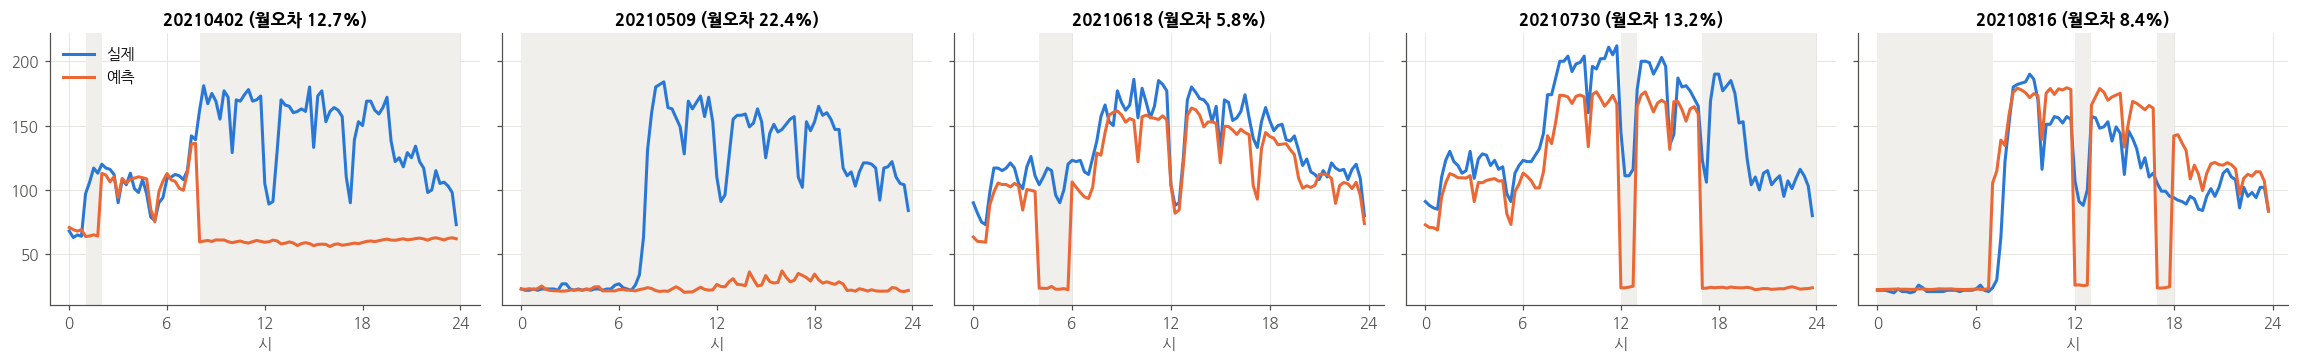

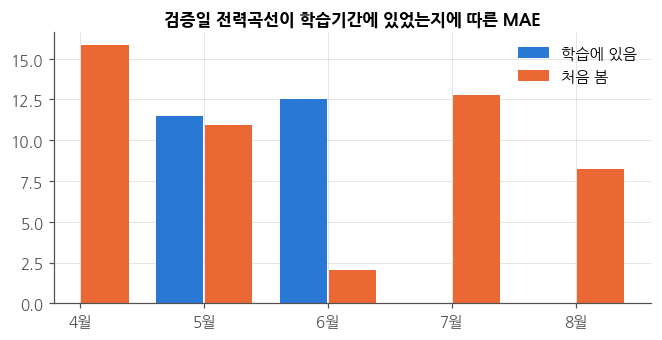

min     max  size
month  생산상태                      
202104 가동     0.895   1.030    30
       생산사이0  2.211   2.608    30
       시작전0   1.806   2.222    30
       종료후0   0.246   1.510    30
       종일0    0.302   0.367    30
202105 가동     0.750   0.975    31
       생산사이0  5.653   7.362    31
       시작전0   0.912   1.229    31
       종료후0   0.472   0.711    31
       종일0    0.523   2.065    31
202106 가동     0.960   1.012    30
       생산사이0  6.994   7.420    30
       시작전0   1.114   1.666    30
       종료후0   0.362   0.560    30
       종일0    0.124   0.151    30
202107 가동     0.886   0.986    29
       생산사이0  6.081   6.916    29
       시작전0   0.683   0.841    29
       종료후0   0.463   1.426    29
       종일0    0.125   0.264    29
202108 가동     1.047   1.123    31
       생산사이0  9.591  10.646    31
       시작전0   1.229   1.737    31
       종료후0   0.433   1.417    31
       종일0    0.367   0.492    31

In [16]:
# 날짜별 월 오차 기여 비중
day_error = errors.groupby(["month", "날짜"])["행_MAE"].sum()
day_share = 100 * day_error / day_error.groupby("month").transform("sum")
display(day_share.groupby("month", group_keys=False).nlargest(3).round(2).to_frame("월오차비중_%"))

# 모든 복합조건의 최대 1일 오차 비중
condition = errors[["생산구간", "요일구분", "시간대"]].astype(str).agg(" / ".join, axis=1).rename("조건")
condition_day = errors.groupby([errors["month"], condition, errors["날짜"]])["행_MAE"].sum()
top_day_share = 100 * condition_day.groupby(level=[0, 1]).max() / condition_day.groupby(level=[0, 1]).sum()
display(top_day_share.unstack("month").reindex(index=condition_month_matrix.index, columns=MONTHS).round(1))

# 검증일 전력곡선의 fold 학습기간(검증월 이전) 내 동일 곡선 유무
curves = raw.groupby("날짜")[POWER].apply(lambda day: day.to_numpy().tobytes())
first_date = curves.index.to_series().groupby(curves.to_numpy()).transform("min")
errors["학습곡선"] = np.where(errors["날짜"].map(first_date).floordiv(100).lt(errors["month"]), "학습에 있음", "처음 봄")
display(errors.groupby(["month", "학습곡선"]).agg(
    날짜수=("날짜", "nunique"), MAE=("행_MAE", "mean"), 편향=("편향", "mean"),
).round(3).unstack("학습곡선"))

# 월별 오차 기여 최대일 실제·예측 15분 전력, 회색 = 생산량 0 시간
top_days = day_error.groupby("month").idxmax()
fig, axes = plt.subplots(1, len(top_days), figsize=(4.2 * len(top_days), 3.4), sharey=True)
for ax, (month, day) in zip(np.atleast_1d(axes), top_days):
    rows = errors.loc[errors["날짜"].eq(day)].sort_values("시간")
    for hour in rows.loc[rows["생산량"].eq(0), "시간"]:
        ax.axvspan(hour, hour + 1, color=NEUTRAL, lw=0)
    time = np.arange(len(rows) * 4) / 4 + rows["시간"].min()
    ax.plot(time, rows[POWER].to_numpy().ravel(), color=BLUE, label="실제")
    ax.plot(time, rows[[f"pred_{p}" for p in POWER]].to_numpy().ravel(), color=ORANGE, label="예측")
    ax.set_xticks(range(0, 25, 6))
    ax.set_xlabel("시")
    ax.set_title(f"{day} (월오차 {day_share.loc[(month, day)]:.1f}%)")
np.atleast_1d(axes)[0].legend()
plt.tight_layout()
plt.show()

curve_mae = errors.groupby(["month", "학습곡선"])["행_MAE"].mean().unstack("학습곡선").reindex(MONTHS)
fig, ax = plt.subplots(figsize=(7, 3.2))
for offset, (name, color) in zip((-.2, .2), (("학습에 있음", BLUE), ("처음 봄", ORANGE))):
    if name in curve_mae:
        ax.bar(np.arange(len(MONTHS)) + offset, curve_mae[name], .38, color=color, label=name)
ax.set_xticks(range(len(MONTHS)), [month_label(m) for m in MONTHS])
ax.set_title("검증일 전력곡선이 학습기간에 있었는지에 따른 MAE")
ax.legend()
plt.show()
# 하루 제외 민감도: 날짜 하나를 빼도 조건 MAE / 해당 월 전체 MAE의 방향이 유지되는지 확인
loo_rows = []
for month, part in errors.groupby("month"):
    for day in part["날짜"].unique():
        remaining = part.loc[part["날짜"].ne(day)]
        for state, group in remaining.groupby("생산상태"):
            loo_rows.append({"month": month, "생산상태": state, "제외일": day,
                             "MAE배수": group["행_MAE"].mean() / remaining["행_MAE"].mean()})
state_loo = pd.DataFrame(loo_rows).groupby(["month", "생산상태"])["MAE배수"].agg(["min", "max", "size"])
display(state_loo.round(3))


### 9. 최대피크 발생 조건

- 1~3월 시간최대 전력의 95분위를 표시용 기준으로 사용. 4~8월 모든 날짜를 유지한다.
- 조건별 발생률·전체 평균 대비 배수·표본 수, 월내 stationary bootstrap의 점별 95% 구간. 그림은 7일 블록, 표는 1·3·7일 모두 보고.

,기준기간_시간최대_임계값
0.900,177.100
0.950,185.000
0.975,190.025


분석일 151일 / 모든 검증일 유지 / 피크 시간 비율 6.8%


,202104,202105,202106,202107,202108
검증일수,30,31,30,29,31
분석일수,30,31,30,29,31


시간별 피크율


,시간행수,날짜수,피크수,평균시간최대,평균생산량,피크율_%,피크비중_%,피크율배수,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일,배수하한,배수상한
시간,,,,,,,,,,,,,,,,,,,
0,151,151,0,53.58,100.03,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
1,151,151,0,78.83,111.49,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
2,151,151,0,79.17,135.02,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
3,151,151,0,78.44,120.64,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
4,151,151,0,78.33,103.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
5,151,151,0,76.09,97.59,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
6,151,151,0,79.62,140.99,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
7,151,151,0,107.52,748.84,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
8,151,151,40,131.89,509.38,26.49,16.13,3.87,3.34,4.43,2000,3.38,4.39,2000,3.47,4.35,2000,3.47,4.35


...

,시간행수,날짜수,피크수,평균시간최대,평균생산량,피크율_%,피크비중_%,피크율배수,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일,배수하한,배수상한
생산구간,,,,,,,,,,,,,,,,,,,
"(0.0,108.0]",528,120,0,111.43,48.96,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
"(1033.5,inf]",681,112,135,166.45,2010.12,19.82,54.44,2.90,2.54,3.30,2000,2.55,3.32,2000,2.60,3.23,2000,2.60,3.23
"(108.0,458.0]",534,113,22,119.59,246.02,4.12,8.87,0.60,0.41,0.81,2000,0.43,0.81,2000,0.45,0.78,2000,0.45,0.78
"(458.0,1033.5]",484,115,89,158.83,740.87,18.39,35.89,2.69,2.26,3.16,2000,2.31,3.16,2000,2.38,3.09,2000,2.38,3.09
0,1397,134,2,36.88,0.00,0.14,0.81,0.02,0.00,0.07,2000,0.00,0.06,2000,0.00,0.06,2000,0.00,0.06


생산상태별 피크율


,시간행수,날짜수,피크수,평균시간최대,평균생산량,피크율_%,피크비중_%,피크율배수,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일,배수하한,배수상한
생산상태,,,,,,,,,,,,,,,,,,,
가동,2227,122,246,140.52,846.29,11.05,99.19,1.61,1.47,1.79,2000,1.46,1.81,2000,1.48,1.77,2000,1.48,1.77
생산사이0,86,56,0,113.43,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
시작전0,228,61,0,45.35,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
종료후0,387,36,2,34.65,0.00,0.52,0.81,0.08,0.00,0.26,2000,0.00,0.24,2000,0.00,0.21,2000,0.00,0.21
종일0,696,29,0,25.90,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN


기온구간별 피크율


,시간행수,날짜수,피크수,평균시간최대,평균생산량,피크율_%,피크비중_%,피크율배수,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일,배수하한,배수상한
기온구간,,,,,,,,,,,,,,,,,,,
"(1.8,7.2]",47,9,0,77.72,164.74,0.00,0.0,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
"(10.9,inf]",3418,151,248,102.32,538.39,7.26,100.0,1.06,1.04,1.08,2000,1.03,1.09,2000,1.03,1.09,2000,1.03,1.09
"(7.2,10.9]",159,25,0,69.70,231.07,0.00,0.0,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN


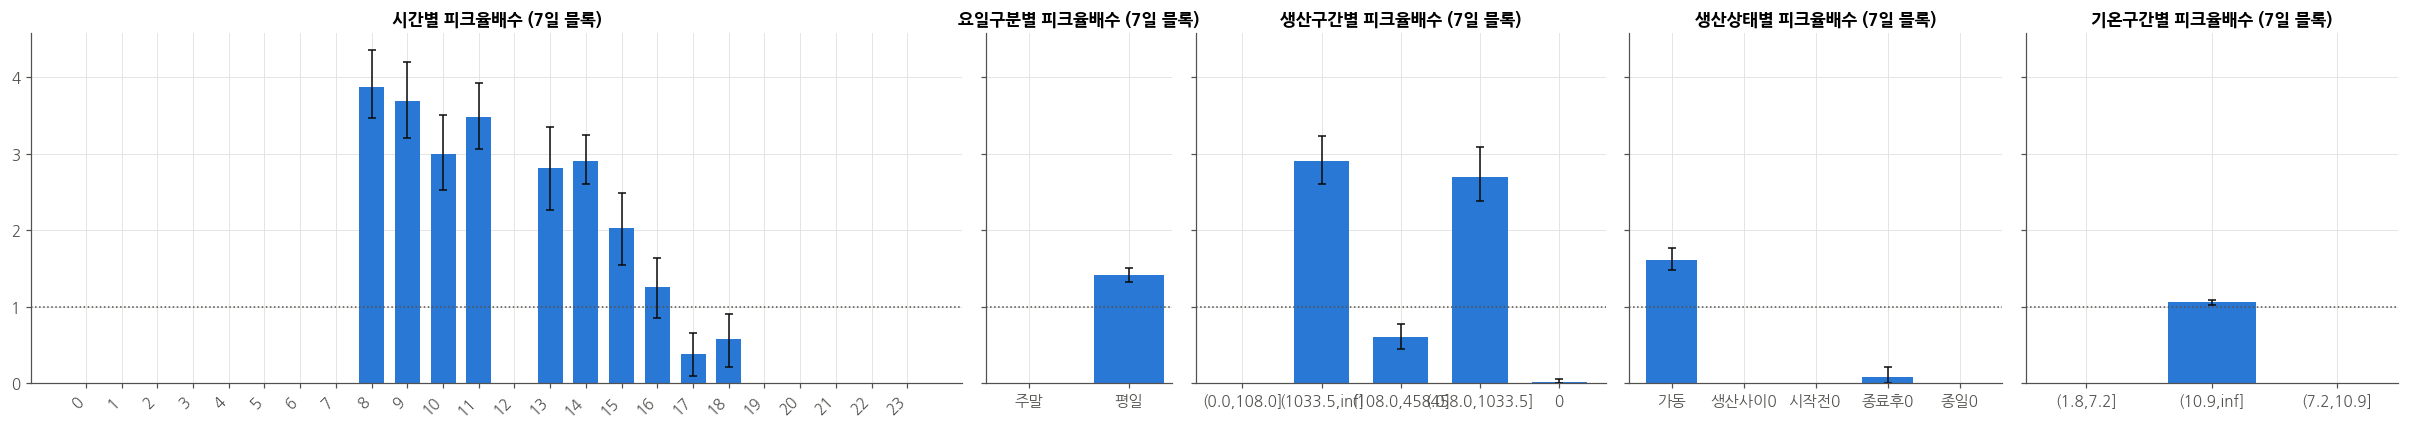

In [17]:
# 피크 임계값은 검증 전 기준기간에서 결정. 실제/예측 모두 같은 기준 적용.
PEAK_QUANTILES = (.90, .95, .975)
peak_thresholds = reference[POWER].max(axis=1).quantile(PEAK_QUANTILES)
PEAK_LEVEL = float(peak_thresholds.loc[.95])
peak_df = add_conditions(raw.loc[raw["날짜"].floordiv(100).isin(MONTHS)].copy())
display(peak_thresholds.rename("기준기간_시간최대_임계값").to_frame())

peak_df["시간최대"] = peak_df[POWER].max(axis=1)  # 시간 내 15분 전력 최댓값
peak_df["피크"] = peak_df["시간최대"].ge(PEAK_LEVEL)
first_on = peak_df["시간"].where(peak_df["생산량"].gt(0)).groupby(peak_df["날짜"]).transform("min")
peak_df["첫생산후경과"] = peak_df["시간"] - first_on  # 자정 이후 첫 생산 시각 기준(음수 = 첫 생산 전)
peak_df["직전생산량"] = peak_df.groupby("날짜")["생산량"].shift(1)
print(f"분석일 {peak_df['날짜'].nunique()}일 / 모든 검증일 유지 / 피크 시간 비율 {peak_df['피크'].mean():.1%}")
display(pd.DataFrame({
    "검증일수": errors.groupby("month")["날짜"].nunique(),
    "분석일수": peak_df.groupby(peak_df["날짜"].floordiv(100))["날짜"].nunique(),
}).fillna(0).astype(int).T)


def peak_rates(keys):
    table = peak_df.groupby(keys, observed=True).agg(
        시간행수=("피크", "size"), 날짜수=("날짜", "nunique"), 피크수=("피크", "sum"),
        평균시간최대=("시간최대", "mean"), 평균생산량=("생산량", "mean"),
    ).reset_index()
    table["피크율_%"] = 100 * table["피크수"] / table["시간행수"]
    table["피크비중_%"] = 100 * table["피크수"] / peak_df["피크"].sum()
    table["피크율배수"] = table["피크율_%"] / (100 * peak_df["피크"].mean())
    table["조건"] = table[keys].astype(str).agg(" / ".join, axis=1)
    table = table.join(day_bootstrap_ci(peak_df, keys, "피크"), on="조건")
    return table.drop(columns="조건").set_index(keys).round(2)


peak_axes = (["시간"], ["요일구분"], ["생산구간"], ["생산상태"], ["기온구간"])
fig, axes = plt.subplots(1, len(peak_axes), figsize=(22, 4), gridspec_kw={"width_ratios": [5, 1, 2.2, 2, 2]}, sharey=True)
for ax, keys in zip(axes, peak_axes):
    table = peak_rates(keys)
    print(f"{keys[0]}별 피크율")
    display(table)
    ci_bars(ax, table, "피크율배수", "배수하한", "배수상한", f"{keys[0]}별 피크율배수 (7일 블록)")
plt.tight_layout()
plt.show()

In [18]:
combo_peaks = peak_rates(["요일구분", "시간대", "생산구간"])
# 효과가 크거나 구간 하한이 1을 넘는 조건만 선별하지 않음
display(combo_peaks.sort_index())


시간행수  날짜수  피크수  평균시간최대    평균생산량  피크율_%  피크비중_%  \
요일구분 시간대    생산구간                                                             
주말   00~05시 (0.0,108.0]       56   19    0  102.70    49.34   0.00    0.00   
            (1033.5,inf]       2    2    0  106.50  1244.00   0.00    0.00   
            (108.0,458.0]     30   12    0  103.13   224.10   0.00    0.00   
            (458.0,1033.5]     7    7    0  103.00   637.14   0.00    0.00   
            0                169   36    0   32.57     0.00   0.00    0.00   
     06~11시 (0.0,108.0]        6    6    0   87.67    33.50   0.00    0.00   
            (1033.5,inf]      10   10    0   90.70  1575.10   0.00    0.00   
            (108.0,458.0]      9    8    0  102.44   272.33   0.00    0.00   
            (458.0,1033.5]    13   12    0   95.62   676.69   0.00    0.00   
            0                226   44    0   27.76     0.00   0.00    0.00   
     12~17시 0                264   44    0   26.77     0.00   0.00    0.00   
     18~23시 0                264   44    0   25.39     0.00   0.00    0.00   
평일   00~05시 (0.0,108.0]      186   72    0  102.82    50.54   0.00    0.00   
            (1033.5,inf]       5    4    0  104.00  1585.00   0.00    0.00   
            (108.0,458.0]    182   67    0  100.09   236.62   0.00    0.00   
            (458.0,1033.5]    38   32    0   98.18   631.79   0.00    0.00   
            0                231   75    0   44.31     0.00   0.00    0.00   
     06~11시 (0.0,108.0]       39   37    0  117.36    52.21   0.00    0.00   
            (1033.5,inf]     225  100   73  173.79  1723.14  32.44   29.44   
            (108.0,458.0]     72   55   12  142.78   277.08  16.67    4.84   
            (458.0,1033.5]   218   95   60  171.60   754.61  27.52   24.19   
            0                 88   36    0   54.50     0.00   0.00    0.00   
     12~17시 (0.0,108.0]       30   29    0  129.47    52.93   0.00    0.00   
            (1033.5,inf]     291   99   58  171.26  2145.35  19.93   23.39   
            (108.0,458.0]     92   67   10  145.82   287.28  10.87    4.03   
            (458.0,1033.5]   163   83   28  166.75   755.40  17.18   11.29   
            0                 66   24    1   65.03     0.00   1.52    0.40   
     18~23시 (0.0,108.0]      211   92    0  118.36    46.74   0.00    0.00   
            (1033.5,inf]     148   92    4  153.87  2234.62   2.70    1.61   
            (108.0,458.0]    149   81    0  120.36   219.85   0.00    0.00   
            (458.0,1033.5]    45   41    1  146.47   748.40   2.22    0.40   
            0                 89   37    1   74.78     0.00   1.12    0.40   

                            피크율배수  하한_1일  상한_1일  유효재표집_1일  하한_3일  상한_3일  \
요일구분 시간대    생산구간                                                          
주말   00~05시 (0.0,108.0]      0.00    NaN    NaN      2000    NaN    NaN   
            (1033.5,inf]     0.00    NaN    NaN      1720    NaN    NaN   
            (108.0,458.0]    0.00    NaN    NaN      2000    NaN    NaN   
            (458.0,1033.5]   0.00    NaN    NaN      2000    NaN    NaN   
            0                0.00    NaN    NaN      2000    NaN    NaN   
     06~11시 (0.0,108.0]      0.00    NaN    NaN      1993    NaN    NaN   
            (1033.5,inf]     0.00    NaN    NaN      2000    NaN    NaN   
            (108.0,458.0]    0.00    NaN    NaN      2000    NaN    NaN   
            (458.0,1033.5]   0.00    NaN    NaN      2000    NaN    NaN   
            0                0.00    NaN    NaN      2000    NaN    NaN   
     12~17시 0                0.00    NaN    NaN      2000    NaN    NaN   
     18~23시 0                0.00    NaN    NaN      2000    NaN    NaN   
평일   00~05시 (0.0,108.0]      0.00    NaN    NaN      2000    NaN    NaN   
            (1033.5,inf]     0.00    NaN    NaN      1956    NaN    NaN   
            (108.0,458.0]    0.00    NaN    NaN      2000    NaN    NaN   
            (458.0,1033.5]   0.00    NaN    NaN      2000    NaN    NaN   
            0            

생산량           직전생산량           기온        첫생산후경과       
         mean  median    mean median  mean median   mean median
피크                                                             
False   459.8    51.5   493.7   60.0  20.4   21.5    9.7   10.0
True   1340.9  1130.5  1128.9  929.0  26.4   26.8    9.4   10.0

,시간행수,날짜수,피크수,평균시간최대,평균생산량,피크율_%,피크비중_%,피크율배수,하한_1일,상한_1일,유효재표집_1일,하한_3일,상한_3일,유효재표집_3일,하한_7일,상한_7일,유효재표집_7일,배수하한,배수상한
첫생산후경과,,,,,,,,,,,,,,,,,,,
-8.0,19,19,0,26.16,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-7.0,24,24,0,30.54,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-6.0,24,24,0,33.62,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-5.0,24,24,0,34.08,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-4.0,24,24,0,33.00,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-3.0,25,25,0,34.32,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-2.0,27,27,0,38.15,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
-1.0,61,61,0,78.75,0.00,0.00,0.00,0.00,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN,2000,NaN,NaN
0.0,122,122,7,100.16,289.53,5.74,2.82,0.84,0.29,1.43,2000,0.39,1.42,2000,0.45,1.30,2000,0.45,1.30


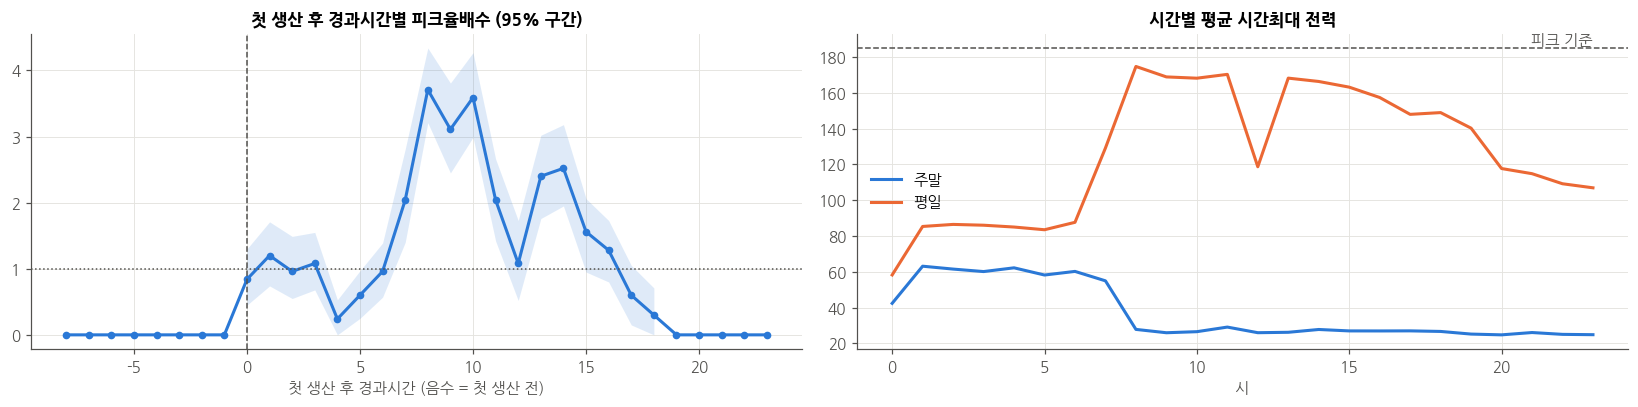

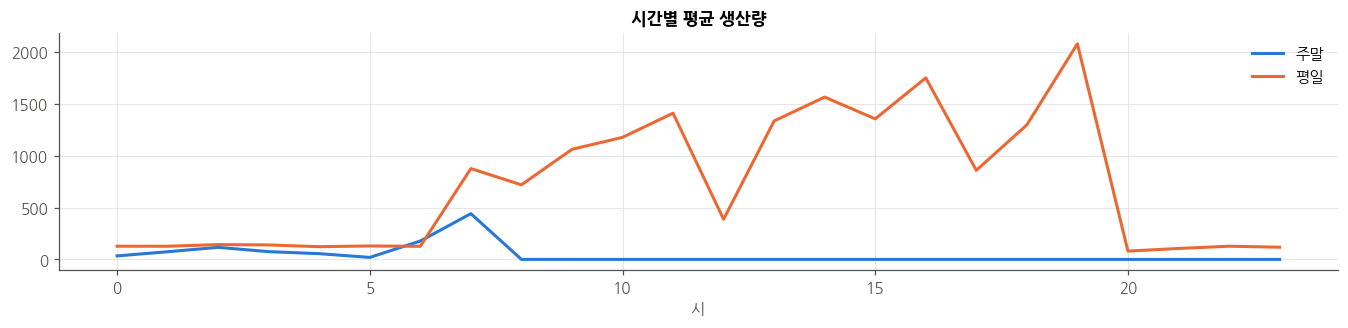

In [19]:
display(peak_df.groupby("피크")[["생산량", "직전생산량", "기온", "첫생산후경과"]].agg(["mean", "median"]).round(1))
display(peak_rates(["첫생산후경과"]))

elapsed = peak_rates(["첫생산후경과"])
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].plot(elapsed.index, elapsed["피크율배수"], color=BLUE, marker="o", ms=4)
axes[0].fill_between(elapsed.index, elapsed["배수하한"], elapsed["배수상한"], color=BLUE, alpha=.15, lw=0)
axes[0].axhline(1, color=MUTED, ls=":", lw=1)
axes[0].axvline(0, color=MUTED, ls="--", lw=1)
axes[0].set_xlabel("첫 생산 후 경과시간 (음수 = 첫 생산 전)")
axes[0].set_title("첫 생산 후 경과시간별 피크율배수 (95% 구간)")
for color, (name, part) in zip((BLUE, ORANGE), peak_df.groupby("요일구분")):
    axes[1].plot(part.groupby("시간")["시간최대"].mean(), color=color, label=name)
axes[1].axhline(PEAK_LEVEL, color=MUTED, ls="--", lw=1)
axes[1].text(23, PEAK_LEVEL, "피크 기준", color=MUTED, ha="right", va="bottom")
axes[1].set_xlabel("시")
axes[1].set_title("시간별 평균 시간최대 전력")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(15, 2.8))
for color, (name, part) in zip((BLUE, ORANGE), peak_df.groupby("요일구분")):
    ax.plot(part.groupby("시간")["생산량"].mean(), color=color, label=name)
ax.set_xlabel("시")
ax.set_title("시간별 평균 생산량")
ax.legend()
plt.show()

최대발생시각,0,1,2,3,4,5,6,8,9,10,11,12,13,14,15,16,18,21,23
요일구분,,,,,,,,,,,,,,,,,,,
주말,1,13,9,2,6,1,2,3,0,0,2,2,0,0,1,0,1,1,0
평일,0,1,0,1,1,0,2,53,5,11,11,0,12,2,6,1,0,0,1


,상관
일생산량,0.739
시간최대생산량,0.720
가동시간수,0.675
평균기온,0.140
최고기온,0.090
최대발생시각,0.475


,일최대전력,일생산량,가동시간수,평균기온
요일구분,,,,
주말,70.0,991.7,3.0,21.0
평일,179.9,17206.2,19.6,20.8


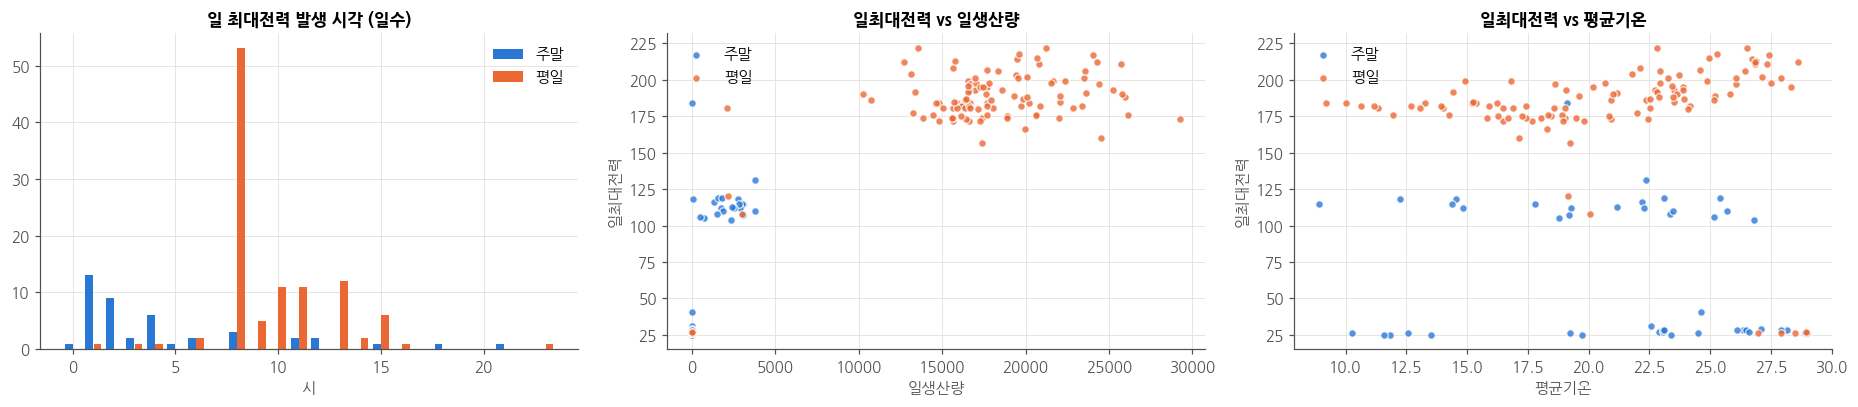

In [20]:
daily = peak_df.groupby("날짜").agg(
    일최대전력=("시간최대", "max"), 일생산량=("생산량", "sum"), 시간최대생산량=("생산량", "max"),
    가동시간수=("생산량", lambda values: values.gt(0).sum()), 평균기온=("기온", "mean"), 최고기온=("기온", "max"),
    요일구분=("요일구분", "first"),
)
daily["최대발생시각"] = peak_df.loc[peak_df.groupby("날짜")["시간최대"].idxmax()].set_index("날짜")["시간"]
display(daily.groupby(["요일구분", "최대발생시각"]).size().unstack(fill_value=0))
display(daily.drop(columns="요일구분").corr(method="spearman")["일최대전력"].drop("일최대전력").round(3).to_frame("상관"))
display(daily.groupby("요일구분")[["일최대전력", "일생산량", "가동시간수", "평균기온"]].mean().round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
hour_counts = daily.groupby(["최대발생시각", "요일구분"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0)
for offset, (name, color) in zip((-.2, .2), (("주말", BLUE), ("평일", ORANGE))):
    if name in hour_counts:
        axes[0].bar(hour_counts.index + offset, hour_counts[name], .38, color=color, label=name)
axes[0].set_xlabel("시")
axes[0].set_title("일 최대전력 발생 시각 (일수)")
axes[0].legend()
for ax, column in zip(axes[1:], ["일생산량", "평균기온"]):
    for color, (name, part) in zip((BLUE, ORANGE), daily.groupby("요일구분")):
        ax.scatter(part[column], part["일최대전력"], s=24, color=color, alpha=.8, label=name, edgecolors="white", linewidths=.8)
    ax.set_xlabel(column)
    ax.set_ylabel("일최대전력")
    ax.set_title(f"일최대전력 vs {column}")
    ax.legend()
plt.tight_layout()
plt.show()

### 9-1. 피크 임계값·반복곡선 가중치 민감도

- 90·95·97.5분위 기준을 모두 평가. 전체 검증일의 동일 가중치와 곡선별 총 가중치 1인 결과 비교.
- 조건별 피크율은 각 조건 내부의 비율, 피크 비중은 전체 피크 중 해당 조건의 비율이다.
- 가중 결과는 독립성 보정이나 원본일 복원이 아니다. 희소·무피크 조건도 그대로 보고한다.

In [21]:
# 같은 전력곡선 그룹의 모든 날짜를 유지하고 그룹별 총 가중치만 같게 함
evaluation_curves = curves.reindex(peak_df["날짜"].unique())
curve_counts = evaluation_curves.value_counts()
curve_weights = evaluation_curves.map(lambda curve: 1 / curve_counts[curve])
peak_df["곡선가중치"] = peak_df["날짜"].map(curve_weights)
peak_sensitivity_rows = []
for quantile, threshold in peak_thresholds.items():
    flags = peak_df["시간최대"].ge(threshold).astype(float)
    for scheme, weights in (("시간동일", pd.Series(1., index=peak_df.index)), ("곡선동일", peak_df["곡선가중치"])):
        weighted_peaks = flags * weights
        for axis in ["요일구분", "시간", "생산구간", "생산상태", "기온구간"]:
            for condition, group in peak_df.groupby(axis, observed=True):
                idx = group.index
                peak_sensitivity_rows.append({
                    "분위": quantile, "임계값": threshold, "가중방식": scheme, "분석축": axis, "조건": str(condition),
                    "시간수": len(group), "날짜수": group["날짜"].nunique(),
                    "피크발생률_%": 100 * weighted_peaks.loc[idx].sum() / weights.loc[idx].sum(),
                    "전체피크중비중_%": 100 * weighted_peaks.loc[idx].sum() / weighted_peaks.sum() if weighted_peaks.sum() else np.nan,
                })
peak_condition_sensitivity = pd.DataFrame(peak_sensitivity_rows)
display(peak_condition_sensitivity.round(3))

# 반복곡선의 영향은 오차 분석에서도 별도 확인한다.
errors["곡선가중치"] = errors["날짜"].map(curve_weights)
error_weight_rows = []
for (month, state), group in errors.groupby(["month", "생산상태"]):
    for scheme, weights in (("시간동일", np.ones(len(group))), ("곡선동일", group["곡선가중치"])):
        error_weight_rows.append({"month": month, "생산상태": state, "가중방식": scheme,
                                 "시간수": len(group), "날짜수": group["날짜"].nunique(),
                                 "MAE": np.average(group["행_MAE"], weights=weights),
                                 "편향": np.average(group["편향"], weights=weights)})
error_weight_sensitivity = pd.DataFrame(error_weight_rows)
display(error_weight_sensitivity.round(3))

,분위,임계값,가중방식,분석축,조건,시간수,날짜수,피크발생률_%,전체피크중비중_%
0,0.900,177.100,시간동일,요일구분,주말,1056,44,0.095,0.247
1,0.900,177.100,시간동일,요일구분,평일,2568,107,15.732,99.753
2,0.900,177.100,시간동일,시간,0,151,151,0.000,0.000
3,0.900,177.100,시간동일,시간,1,151,151,0.000,0.000
4,0.900,177.100,시간동일,시간,2,151,151,0.000,0.000
...,...,...,...,...,...,...,...,...,...
229,0.975,190.025,곡선동일,생산상태,종료후0,387,36,0.000,0.000
230,0.975,190.025,곡선동일,생산상태,종일0,696,29,0.000,0.000
231,0.975,190.025,곡선동일,기온구간,"(1.8,7.2]",47,9,0.000,0.000
232,0.975,190.025,곡선동일,기온구간,"(10.9,inf]",3418,151,4.948,100.000


,month,생산상태,가중방식,시간수,날짜수,MAE,편향
0,202104,가동,시간동일,470,26,14.587,12.001
1,202104,가동,곡선동일,470,26,16.043,13.396
2,202104,생산사이0,시간동일,22,14,37.599,-33.785
3,202104,생산사이0,곡선동일,22,14,38.197,-33.081
4,202104,시작전0,시간동일,51,17,31.770,0.059
5,202104,시작전0,곡선동일,51,17,35.002,-1.227
6,202104,종료후0,시간동일,81,7,19.622,-16.247
7,202104,종료후0,곡선동일,81,7,16.884,-13.134
8,202104,종일0,시간동일,96,4,5.243,4.952
9,202104,종일0,곡선동일,96,4,4.895,4.552


### 10. 피크 시간 예측 성능

- 재현율·정밀도, 일 최대 MAE·편향, 발생 시각 차이

시간행수    MAE     편향  시간최대오차
month  실제피크                             
202104 False   718  15.83   5.69    3.06
       True      2  13.58 -13.45  -16.24
202105 False   739  11.24  -1.30   -3.61
       True      5  12.91 -10.53  -17.99
202106 False   672  11.22  -9.26  -11.76
       True     48  20.44 -19.85  -26.65
202107 False   572  11.34  -6.04   -8.70
       True    124  19.46 -17.69  -24.74
202108 False   675   7.93   0.74   -1.12
       True     69  11.20  -7.59  -14.14

,실제피크,예측피크,적중,재현율_%,정밀도_%
month,,,,,
202104,2,0,0,0.0,NaN
202105,5,0,0,0.0,NaN
202106,48,0,0,0.0,NaN
202107,124,2,1,0.8,50.0
202108,69,21,16,23.2,76.2


,날짜수,일최대MAE,일최대편향,최대과소예측,시각일치율,평균시각차
month,,,,,,
202104,30,7.40,-0.77,-44.72,26.67,4.37
202105,31,15.10,-3.43,-146.96,32.26,3.39
202106,30,16.30,-16.30,-52.54,23.33,3.47
202107,29,20.39,-15.79,-40.85,17.24,3.03
202108,31,7.50,-4.39,-30.56,9.68,5.10


,놓친피크수,놓친피크_기준초과평균,놓친피크_기준초과최대,하루평균오경보
month,,,,
202104,2,8.00,14.0,0.00
202105,5,4.80,14.0,0.00
202106,48,7.10,37.0,0.00
202107,123,10.67,37.0,0.03
202108,53,7.23,30.0,0.16


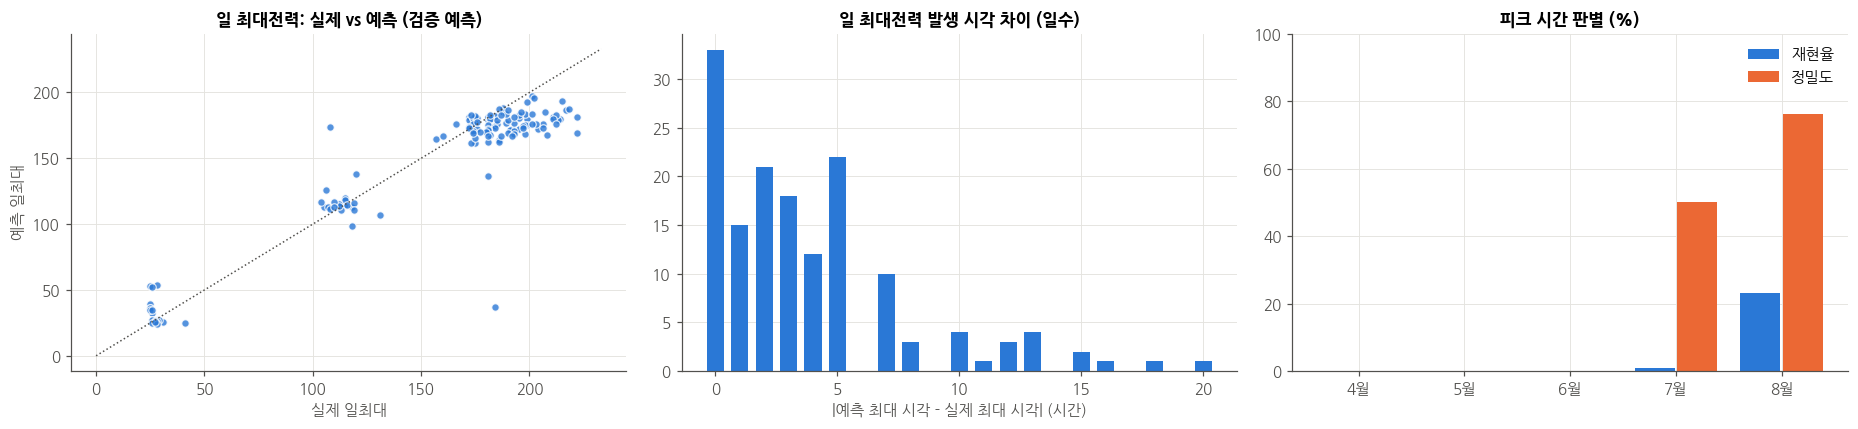

In [22]:
# 4~8월 OOF: 실제 피크 시간 오차, 피크 판별 성능
actual_max = errors[POWER].max(axis=1)
predicted_max = errors[[f"pred_{p}" for p in POWER]].max(axis=1)
errors["실제피크"] = actual_max.ge(PEAK_LEVEL)
errors["예측피크"] = predicted_max.ge(PEAK_LEVEL)
errors["시간최대오차"] = predicted_max - actual_max  # 음수 = 피크 과소예측
display(errors.groupby(["month", "실제피크"]).agg(
    시간행수=("row_id", "size"), MAE=("행_MAE", "mean"), 편향=("편향", "mean"),
    시간최대오차=("시간최대오차", "mean"),
).round(2))
errors["적중"] = errors["실제피크"] & errors["예측피크"]
peak_hits = errors.groupby("month")[["실제피크", "예측피크", "적중"]].sum()
peak_hits["재현율_%"] = 100 * peak_hits["적중"] / peak_hits["실제피크"]
peak_hits["정밀도_%"] = 100 * peak_hits["적중"] / peak_hits["예측피크"]
display(peak_hits.round(1))

# 일 최대전력: 크기 오차, 발생 시각 차이
hourly = errors[["month", "날짜", "시간"]].assign(실제=actual_max, 예측=predicted_max)
actual_at = hourly.loc[hourly.groupby("날짜")["실제"].idxmax()].set_index("날짜")
predicted_at = hourly.loc[hourly.groupby("날짜")["예측"].idxmax()].set_index("날짜")
day_eval = pd.DataFrame({
    "month": actual_at["month"], "실제일최대": actual_at["실제"], "예측일최대": predicted_at["예측"],
    "일최대오차": predicted_at["예측"] - actual_at["실제"],
    "시각차": (predicted_at["시간"] - actual_at["시간"]).abs(),
})
display(day_eval.groupby("month").agg(
    날짜수=("실제일최대", "size"), 일최대MAE=("일최대오차", lambda values: values.abs().mean()),
    일최대편향=("일최대오차", "mean"), 최대과소예측=("일최대오차", "min"),
    시각일치율=("시각차", lambda values: 100 * values.eq(0).mean()),
    평균시각차=("시각차", "mean"),
).round(2))
missed = errors["실제피크"] & ~errors["예측피크"]
false_alarm = errors["예측피크"] & ~errors["실제피크"]
display(pd.DataFrame({
    "놓친피크수": missed.groupby(errors["month"]).sum(),
    "놓친피크_기준초과평균": (actual_max - PEAK_LEVEL)[missed].groupby(errors["month"]).mean(),
    "놓친피크_기준초과최대": (actual_max - PEAK_LEVEL)[missed].groupby(errors["month"]).max(),
    "하루평균오경보": false_alarm.groupby(errors["month"]).sum() / errors.groupby("month")["날짜"].nunique(),
}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
limit = [0, max(day_eval["실제일최대"].max(), day_eval["예측일최대"].max()) * 1.05]
axes[0].scatter(day_eval["실제일최대"], day_eval["예측일최대"], s=24, color=BLUE, alpha=.8, edgecolors="white", linewidths=.8)
axes[0].plot(limit, limit, color=MUTED, ls=":", lw=1)
axes[0].set_xlabel("실제 일최대")
axes[0].set_ylabel("예측 일최대")
axes[0].set_title("일 최대전력: 실제 vs 예측 (검증 예측)")
lag = day_eval["시각차"].value_counts().sort_index()
axes[1].bar(lag.index, lag.to_numpy(), color=BLUE, width=.7)
axes[1].set_xlabel("|예측 최대 시각 - 실제 최대 시각| (시간)")
axes[1].set_title("일 최대전력 발생 시각 차이 (일수)")
x = np.arange(len(peak_hits))
axes[2].bar(x - .2, peak_hits["재현율_%"], .38, color=BLUE, label="재현율")
axes[2].bar(x + .2, peak_hits["정밀도_%"], .38, color=ORANGE, label="정밀도")
axes[2].set_xticks(x, [month_label(m) for m in peak_hits.index])
axes[2].set_ylim(0, 100)
axes[2].set_title("피크 시간 판별 (%)")
axes[2].legend()
plt.tight_layout()
plt.show()

### 10-1. 피크 미탐지·오경보 전체 집계

- 한 시간의 15분 전력 최댓값을 기준으로 TP·FN·FP·TN 계산. 연속된 피크도 시간별로 각각 집계.
- 재현율 = TP / 실제 피크, 미탐지율 = FN / 실제 피크, 정밀도 = TP / 예측 피크, 오경보율 = FP / 실제 비피크.
- 전체 비율은 월별 비율의 평균이 아니라 건수를 합산해 계산. 예측 피크가 없으면 정밀도는 결측.
- 4~8월 OOF는 모델 튜닝에도 사용된 개발용 진단 자료임. 오경보가 적어도 미탐지율이 높으면 피크 경보 성능이 양호하다고 해석하지 않음.


In [23]:
# 앞 셀의 peak_hits와 errors를 이용해 월별·전체 혼동행렬 집계
peak_confusion = peak_hits[["실제피크", "예측피크", "적중"]].rename(columns={"적중": "TP"}).copy()
peak_confusion["시간수"] = errors.groupby("month").size()
peak_confusion["날짜수"] = errors.groupby("month")["날짜"].nunique()
peak_confusion["FN"] = peak_confusion["실제피크"] - peak_confusion["TP"]
peak_confusion["FP"] = peak_confusion["예측피크"] - peak_confusion["TP"]
peak_confusion["TN"] = peak_confusion["시간수"] - peak_confusion["실제피크"] - peak_confusion["FP"]
peak_confusion.loc["전체"] = peak_confusion.sum()
assert (peak_confusion[["TP", "FN", "FP", "TN"]] >= 0).all().all()
assert peak_confusion[["TP", "FN", "FP", "TN"]].sum(axis=1).eq(peak_confusion["시간수"]).all()
assert peak_confusion.loc["전체", "FN"] == (errors["실제피크"] & ~errors["예측피크"]).sum()
assert peak_confusion.loc["전체", "FP"] == (~errors["실제피크"] & errors["예측피크"]).sum()

peak_confusion["재현율_%"] = 100 * peak_confusion["TP"] / peak_confusion["실제피크"].replace(0, np.nan)
peak_confusion["미탐지율_%"] = 100 * peak_confusion["FN"] / peak_confusion["실제피크"].replace(0, np.nan)
peak_confusion["정밀도_%"] = 100 * peak_confusion["TP"] / peak_confusion["예측피크"].replace(0, np.nan)
peak_confusion["오경보율_%"] = 100 * peak_confusion["FP"] / (peak_confusion["FP"] + peak_confusion["TN"]).replace(0, np.nan)
peak_confusion["하루평균오경보"] = peak_confusion["FP"] / peak_confusion["날짜수"].replace(0, np.nan)
display(peak_confusion[["시간수", "날짜수", "실제피크", "예측피크", "TP", "FN", "FP", "TN",
                        "재현율_%", "미탐지율_%", "정밀도_%", "오경보율_%", "하루평균오경보"]].round(2))


,시간수,날짜수,실제피크,예측피크,TP,FN,FP,TN,재현율_%,미탐지율_%,정밀도_%,오경보율_%,하루평균오경보
month,,,,,,,,,,,,,
202104,720,30,2,0,0,2,0,718,0.00,100.00,NaN,0.00,0.00
202105,744,31,5,0,0,5,0,739,0.00,100.00,NaN,0.00,0.00
202106,720,30,48,0,0,48,0,672,0.00,100.00,NaN,0.00,0.00
202107,696,29,124,2,1,123,1,571,0.81,99.19,50.00,0.17,0.03
202108,744,31,69,21,16,53,5,670,23.19,76.81,76.19,0.74,0.16
전체,3624,151,248,23,17,231,6,3370,6.85,93.15,73.91,0.18,0.04


### 10-2. 피크 정의별 예측 성능과 경보 임계값의 상충관계

- 실제 피크 정의는 기준기간 90·95·97.5분위. 예측 전력에 같은 기준을 적용한 혼동행렬을 월별·전체로 보고.
- 실제 피크 정의별 AP(average precision)와 PR 곡선으로 예측 경보 임계값 전체 범위를 확인한다. 예측 경보 임계값을 이 자료에서 최적화하지 않는다.
- PR/AP는 시간 단위 탐색적 점추정이며, 연속 피크 사건의 조기 경보나 독립 미래 성능을 의미하지 않는다.

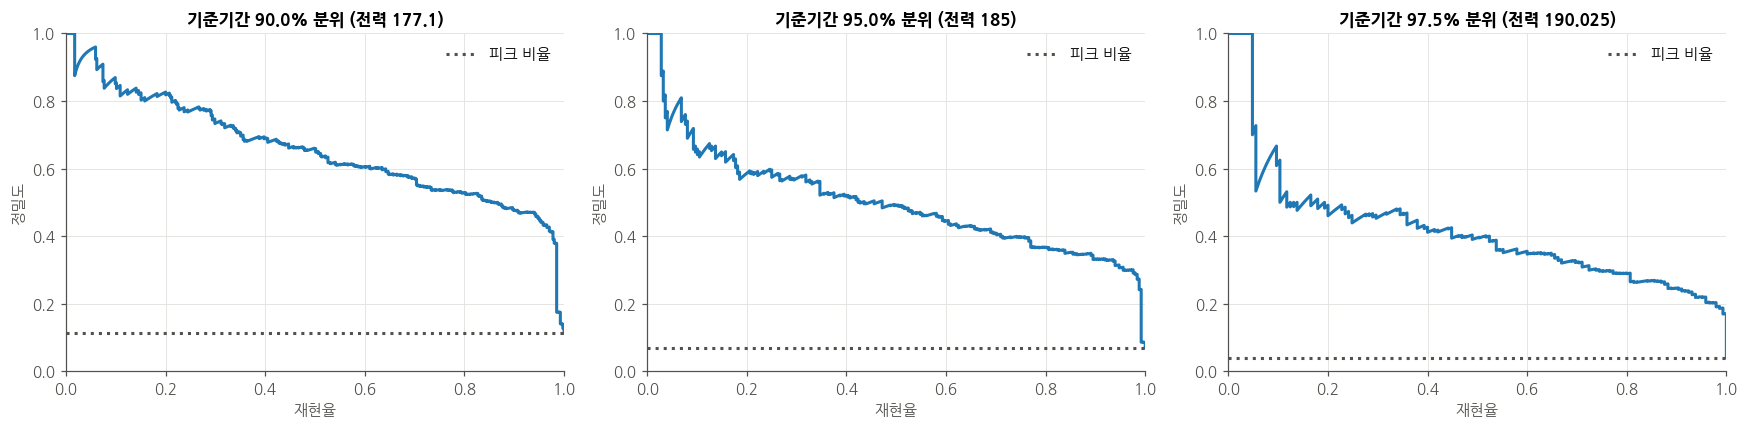

,분위,임계값,month,시간수,TP,FN,FP,TN,재현율_%,정밀도_%,오경보율_%,하루평균오경보,피크비율,AP
0,0.900,177.100,전체,3624,118,287,37,3182,29.1358,76.1290,1.1494,0.2450,0.1118,0.6562
1,0.900,177.100,202104,720,7,27,18,668,20.5882,28.0000,2.6239,0.6000,0.0472,0.2557
2,0.900,177.100,202105,744,1,25,1,717,3.8462,50.0000,0.1393,0.0323,0.0349,0.4212
3,0.900,177.100,202106,720,0,91,0,629,0.0000,NaN,0.0000,0.0000,0.1264,0.6001
4,0.900,177.100,202107,696,44,109,2,541,28.7582,95.6522,0.3683,0.0690,0.2198,0.9229
5,0.900,177.100,202108,744,66,35,16,627,65.3465,80.4878,2.4883,0.5161,0.1358,0.8266
6,0.950,185.000,전체,3624,17,231,6,3370,6.8548,73.9130,0.1777,0.0397,0.0684,0.5018
7,0.950,185.000,202104,720,0,2,0,718,0.0000,NaN,0.0000,0.0000,0.0028,0.0506
8,0.950,185.000,202105,744,0,5,0,739,0.0000,NaN,0.0000,0.0000,0.0067,0.1590
9,0.950,185.000,202106,720,0,48,0,672,0.0000,NaN,0.0000,0.0000,0.0667,0.4891


In [24]:
threshold_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (quantile, threshold) in zip(axes, peak_thresholds.items()):
    for month, part in [("전체", errors), *list(errors.groupby("month"))]:
        actual_peak = part[POWER].max(axis=1).ge(threshold)
        predicted_score = part[[f"pred_{p}" for p in POWER]].max(axis=1)
        predicted_peak = predicted_score.ge(threshold)
        tp = int((actual_peak & predicted_peak).sum())
        fn = int((actual_peak & ~predicted_peak).sum())
        fp = int((~actual_peak & predicted_peak).sum())
        tn = int((~actual_peak & ~predicted_peak).sum())
        assert tp + fn + fp + tn == len(part)
        threshold_rows.append({"분위": quantile, "임계값": threshold, "month": month,
                               "시간수": len(part), "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                               "재현율_%": 100*tp/(tp+fn) if tp+fn else np.nan,
                               "정밀도_%": 100*tp/(tp+fp) if tp+fp else np.nan,
                               "오경보율_%": 100*fp/(fp+tn) if fp+tn else np.nan,
                               "하루평균오경보": fp/part["날짜"].nunique(),
                               "피크비율": actual_peak.mean(),
                               "AP": average_precision_score(actual_peak, predicted_score) if actual_peak.any() else np.nan})
        if month == "전체" and actual_peak.any():
            precision, recall, thresholds = precision_recall_curve(actual_peak, predicted_score)
            ax.plot(recall, precision)
            ax.axhline(actual_peak.mean(), color=MUTED, ls=":", label="피크 비율")
    ax.set_title(f"기준기간 {quantile:.1%} 분위 (전력 {threshold:g})")
    ax.set_xlabel("재현율")
    ax.set_ylabel("정밀도")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend()
plt.tight_layout()
plt.show()
peak_threshold_evaluation = pd.DataFrame(threshold_rows)
display(peak_threshold_evaluation.round(4))

### 11. 생산일정 조정: 제약 확인을 포함한 시나리오 분석

- 전체 검증일 중 평일·생산일을 대상으로 일 총생산량과 기존 가동시간을 보존한다.
- 조정비율 10~100%를 모두 표시하고, 100% 이동으로 생산량 0 상태가 새로 생기는 경우는 별도 표시한다.
- 상한은 1~3월의 시간별 관측 최대 생산량이다. 모든 방안·비율에서 이 범위를 만족하고 새로운 0 상태가 없는 공통 날짜만 별도 비교한다. 그 밖의 날짜도 제외 개수와 결과를 숨기지 않는다.
- 관측 상한은 실제 생산능력이 아니며, 미관측 설비·납기 제약은 검증할 수 없다. 1~9월 학습 모델의 과거 입력 변경에 대한 시뮬레이션으로 인과적 절감량·독립 검증 성능이 아니다. 최적 비율을 선정하지 않는다.

전체 생산일 102일 / 기준기간 관측범위 내 공통 비교일 0일
공통 날짜가 적거나 없으면 범위 내 조정효과에 대한 근거가 부족하다는 결과이며, 제약을 완화해 재선택하지 않습니다.


,대상,방안,조정비율,날짜수,현행평균일최대,변경평균일최대,평균변화,중앙변화,감소일수,증가일수,변경초과시간,새로운0시간,총예측전력변화_%
0,전체_범위외포함,평준화,0.1,102,180.561,180.511,-0.050,-0.016,52,50,63,0,0.190
1,전체_범위외포함,평준화,0.2,102,180.561,180.486,-0.075,0.002,50,52,73,0,0.126
2,전체_범위외포함,평준화,0.3,102,180.561,180.464,-0.097,0.026,48,54,94,0,0.064
3,전체_범위외포함,평준화,0.4,102,180.561,180.445,-0.116,0.052,47,55,161,0,0.005
4,전체_범위외포함,평준화,0.5,102,180.561,180.435,-0.126,0.143,44,58,230,0,-0.055
5,전체_범위외포함,평준화,0.6,102,180.561,180.440,-0.121,0.218,44,58,319,0,-0.117
6,전체_범위외포함,평준화,0.7,102,180.561,180.461,-0.099,0.271,44,58,391,0,-0.184
7,전체_범위외포함,평준화,0.8,102,180.561,180.495,-0.066,0.359,42,60,460,0,-0.257
8,전체_범위외포함,평준화,0.9,102,180.561,180.550,-0.011,0.430,41,61,511,0,-0.339
9,전체_범위외포함,평준화,1.0,102,180.561,180.620,0.059,0.504,41,61,558,0,-0.435


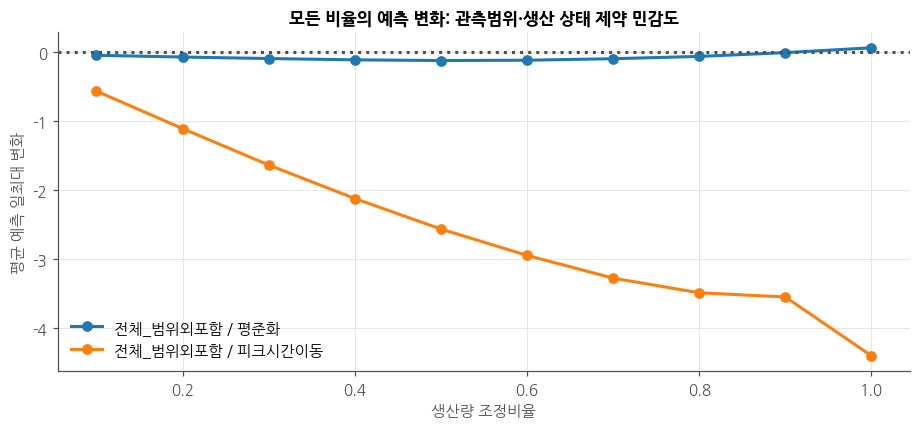

In [25]:
def level_production(frame, share):
    on = frame["생산량"].gt(0)
    on_mean = frame["생산량"].where(on).groupby(frame["날짜"]).transform("mean")
    return frame.assign(생산량=frame["생산량"].where(~on, frame["생산량"] + share * (on_mean - frame["생산량"])))


def predicted_hourly_max(frame):
    return pd.Series(model_v259.predict(frame[INPUTS]).max(axis=1), index=frame.index)


def shift_peak_hour(frame, share):
    on = frame["생산량"].gt(0)
    on_max = predicted_hourly_max(frame)[on]
    source = on_max.groupby(frame.loc[on, "날짜"]).idxmax()
    rest = on_max.drop(source.to_numpy())
    target = rest.groupby(frame.loc[rest.index, "날짜"]).idxmin()
    source = source.loc[target.index]
    moved = share * frame.loc[source, "생산량"].to_numpy()
    shifted = frame.assign(생산량=frame["생산량"].astype(float))
    shifted.loc[source, "생산량"] -= moved
    shifted.loc[target, "생산량"] += moved
    return shifted


sim_days = daily.index[daily["요일구분"].eq("평일") & daily["일생산량"].gt(0)]
sim_base = peak_df.loc[peak_df["날짜"].isin(sim_days), INPUTS].copy()
base_values = model_v259.predict(sim_base)
base_hourly = pd.Series(base_values.max(axis=1), index=sim_base.index)
base_daily = base_hourly.groupby(sim_base["날짜"]).max()
reference_weekday = pd.to_datetime(reference["날짜"].astype(str), format="%Y%m%d").dt.dayofweek.lt(5)
observed_cap = reference.loc[reference_weekday].groupby("시간")["생산량"].max()
base_outside = sim_base["생산량"].gt(sim_base["시간"].map(observed_cap)).groupby(sim_base["날짜"]).any()
scenario_days = []
for kind, adjust in (("평준화", level_production), ("피크시간이동", shift_peak_hour)):
    for share in np.round(np.linspace(.1, 1, 10), 1):
        frame = adjust(sim_base, share)
        assert np.allclose(frame.groupby("날짜")["생산량"].sum(), sim_base.groupby("날짜")["생산량"].sum())
        assert frame["생산량"].ge(0).all() and frame.loc[sim_base["생산량"].eq(0), "생산량"].eq(0).all()
        values = model_v259.predict(frame)
        hourly = pd.Series(values.max(axis=1), index=frame.index)
        outside = frame["생산량"].gt(frame["시간"].map(observed_cap)).groupby(frame["날짜"]).sum()
        new_zero = (sim_base["생산량"].gt(0) & frame["생산량"].eq(0)).groupby(frame["날짜"]).sum()
        for day, group in frame.groupby("날짜"):
            idx = frame.index.get_indexer(group.index)
            scenario_days.append({"방안": kind, "조정비율": share, "날짜": day,
                                  "현행일최대": base_daily.loc[day], "변경일최대": hourly.loc[group.index].max(),
                                  "현행범위초과": bool(base_outside.loc[day]), "변경초과시간": int(outside.loc[day]),
                                  "새로운0시간": int(new_zero.loc[day]),
                                  "현행전력합": base_values[idx].sum(), "변경전력합": values[idx].sum()})
scenario_day_results = pd.DataFrame(scenario_days)
scenario_day_results["범위내상태유지"] = (~scenario_day_results["현행범위초과"]
    & scenario_day_results["변경초과시간"].eq(0) & scenario_day_results["새로운0시간"].eq(0))
# 100% 이동은 상태변화 진단으로만 보고, 공통 비교집단은 10~90%의 두 방안 전체에 동일하게 고정
eligible = scenario_day_results.loc[scenario_day_results["조정비율"].lt(1)].groupby("날짜")["범위내상태유지"].all()
common_days = eligible.index[eligible]
scenario_rows = []
for scope, subset in (("전체_범위외포함", scenario_day_results),
                       ("공통_범위내_10~90%", scenario_day_results.loc[scenario_day_results["날짜"].isin(common_days)
                                                                   & scenario_day_results["조정비율"].lt(1)])):
    for (kind, share), group in subset.groupby(["방안", "조정비율"]):
        change = group["변경일최대"] - group["현행일최대"]
        scenario_rows.append({"대상": scope, "방안": kind, "조정비율": share, "날짜수": len(group),
                              "현행평균일최대": group["현행일최대"].mean(), "변경평균일최대": group["변경일최대"].mean(),
                              "평균변화": change.mean(), "중앙변화": change.median(),
                              "감소일수": int(change.lt(0).sum()), "증가일수": int(change.gt(0).sum()),
                              "변경초과시간": group["변경초과시간"].sum(), "새로운0시간": group["새로운0시간"].sum(),
                              "총예측전력변화_%": 100*(group["변경전력합"].sum()/group["현행전력합"].sum()-1)})
scenario_summary = pd.DataFrame(scenario_rows)
print(f"전체 생산일 {len(sim_days)}일 / 기준기간 관측범위 내 공통 비교일 {len(common_days)}일")
print("공통 날짜가 적거나 없으면 범위 내 조정효과에 대한 근거가 부족하다는 결과이며, 제약을 완화해 재선택하지 않습니다.")
display(scenario_summary.round(3))
fig, ax = plt.subplots(figsize=(10, 4))
for (scope, kind), group in scenario_summary.groupby(["대상", "방안"]):
    ax.plot(group["조정비율"], group["평균변화"], marker="o", label=f"{scope} / {kind}")
ax.axhline(0, color=MUTED, ls=":")
ax.set_xlabel("생산량 조정비율")
ax.set_ylabel("평균 예측 일최대 변화")
ax.set_title("모든 비율의 예측 변화: 관측범위·생산 상태 제약 민감도")
ax.legend()
plt.show()


In [26]:
# 추론 인터페이스 예시(검증성능 아님): 날짜·시간·생산량·기온 → 15·30·45·60분 전력
prediction_inputs = peak_df[INPUTS].tail(24)
final_predictions = prediction_inputs.join(pd.DataFrame(
    model_v259.predict(prediction_inputs), index=prediction_inputs.index, columns=[f"pred_{p}" for p in POWER],
))
display(final_predictions)

,날짜,시간,생산량,기온,pred_15분,pred_30분,pred_45분,pred_60분
5808,20210831,0,204,23.4,73.898188,70.794932,69.672024,69.295564
5809,20210831,1,353,22.9,95.561082,106.412421,110.344587,111.099087
5810,20210831,2,306,22.9,110.082258,110.340452,109.428432,109.772653
5811,20210831,3,378,22.7,96.575003,107.781043,111.216867,111.039718
5812,20210831,4,248,22.9,109.160261,108.824947,107.719912,107.267048
5813,20210831,5,200,22.5,84.348551,75.695055,98.038625,109.663386
5814,20210831,6,266,22.9,111.974208,110.910305,108.790972,107.192588
5815,20210831,7,919,23.5,109.049464,118.635449,144.840470,144.151938
5816,20210831,8,653,24.1,162.734893,180.248602,181.981486,180.877872
5817,20210831,9,942,22.5,172.632726,171.461288,173.507806,175.235815


### 분석 결과와 재현 정보 저장

- 표는 반올림 전 전체 행으로 저장한다. 원자료·모델 해시, 임계값, 구간 경계, 재표집 설정 및 패키지 버전을 함께 기록한다.

In [27]:
import hashlib
import importlib.metadata
import json

ANALYSIS_DIR = ROOT / "analysis/error_review_20261008"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
analysis_tables = {
    "monthly": monthly, "condition_errors": condition_errors, "condition_consistency": condition_consistency,
    "state_loo": state_loo, "continuous_support": continuous_support, "hourly_errors": hourly_errors, "error_weight_sensitivity": error_weight_sensitivity,
    "peak_conditions": combo_peaks, "peak_condition_sensitivity": peak_condition_sensitivity,
    "peak_confusion": peak_confusion, "peak_threshold_evaluation": peak_threshold_evaluation,
    "scenario_days": scenario_day_results, "scenario_summary": scenario_summary,
}
for name, table in analysis_tables.items():
    table.to_csv(ANALYSIS_DIR / f"{name}.csv", encoding="utf-8-sig")
# 저장 모델의 OOF와 별도 CSV가 같은 행·정답·예측인지 검증한다.
artifact_oof = pd.read_csv(Path(PKL_PATH).parent / "V259_oof.csv", index_col="row_id").sort_index()
stored_oof = bundle["oof"].sort_index()
assert artifact_oof.index.equals(stored_oof.index)
assert np.allclose(artifact_oof[[f"pred_{p}" for p in POWER]], stored_oof[POWER], rtol=0, atol=1e-10)
assert np.array_equal(artifact_oof[POWER], raw.loc[artifact_oof.index, POWER])
assert np.allclose(monthly["MAE"], cv_scores.loc[monthly.index, "MAE"], rtol=0, atol=1e-10)
assert peak_df["날짜"].isin(errors["날짜"]).all() and errors["month"].between(202104, 202108).all()
assert len(peak_threshold_evaluation) == len(PEAK_QUANTILES) * (len(MONTHS) + 1)
for weights in bootstrap_weights.values():
    assert np.all(weights.sum(axis=1) == weights.shape[1])
print("PASS: OOF ID·정답·예측·월별 MAE 일치, 기간 분리, 모든 임계값 평가, 재표집 크기 확인")

provenance = {
    "model": str(PKL_PATH), "model_sha256": hashlib.sha256(Path(PKL_PATH).read_bytes()).hexdigest(),
    "data_sha256": hashlib.sha256((ROOT / "data/okm_augumented_2021.csv").read_bytes()).hexdigest(),
    "evaluation": "4~8월 튜닝 OOF; 독립 최종 테스트 아님", "reference": "20210101~20210331",
    "oof_rows": len(errors), "oof_days": int(errors["날짜"].nunique()),
    "peak_thresholds": peak_thresholds.to_dict(), "production_edges": [str(v) for v in PROD_EDGES],
    "temperature_edges": [str(v) for v in TEMP_EDGES], "blocks_days": list(BLOCK_DAYS), "bootstrap_reps": BOOT_REPS,
    "seed": 42, "stratum_seed": "42 + 100 * month.ordinal + block", "versions": {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "arch"]},
}
(ANALYSIS_DIR / "provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
print("분석 저장:", ANALYSIS_DIR)

PASS: OOF ID·정답·예측·월별 MAE 일치, 기간 분리, 모든 임계값 평가, 재표집 크기 확인
분석 저장: /content/drive/MyDrive/kamp_2026/analysis/error_review_20261008
